# Análise Preditiva — Deliverable 2
## Quanto as empresas vão usar e gastar com IA nos próximos seis meses?

**DAMA Intelligence** · Ana Luiza Proença, Gustavo Gomes, Kaique Lira e Ricardo Matteo · Ciência de Dados e Negócios, ESPM, 4º semestre, 2026

Este notebook constrói, valida e aplica modelos de **previsão mensal** para as 18 empresas da base:

1. **Demanda de IA:** requisições por mês, de agosto de 2026 a janeiro de 2027.
2. **Custo de consumo:** tokens nas APIs e plataformas cobradas por uso, convertidos em reais.
3. **Orçamento:** o retrato atual de cada centro de custo (assentos de jul/2026) somado ao consumo previsto, comparado com o orçado.

A previsão abastece o planejamento de licenças da [Pesquisa Operacional](../07_Pesquisa_Operacional_e_Calculo_Aplicado/), que hoje usa o orçamento médio do passado, e os alertas de gestão do DAMA.

### Revisão após o feedback do checkpoint

| Ponto do feedback | O que mudou | Onde |
|---|---|---|
| 1. Diagnóstico da regressão de tendência | Resíduos plotados por empresa, com testes de autocorrelação (Ljung-Box, Durbin-Watson), heterocedasticidade (Breusch-Pagan) e curvatura. A versão em log (crescimento proporcional) entrou como modelo candidato e foi comparada com a linear (crescimento aditivo) nos resíduos e no backtest. A extrapolação da NexoCode foi decomposta em calendário e crescimento | Seções 4, 5.4 e 6.1 |
| 2. O headline esconde a heterogeneidade | sMAPE, WAPE sem a NexoCode, WAPE mediano por empresa e a tabela das 18 empresas, com o peso de cada uma no volume, no resumo | Seções 5.3 e 9 |
| 3. Seleção e teste misturados | O backtest foi dividido no tempo. A escolha do modelo e a calibração da faixa de 80% usam só previsões com alvo até abr/2026; as origens de abr a jun/2026 só confirmam. O mesmo vale para os tokens, que passaram a ter faixa própria. No D1, a validação cruzada e o limiar passaram a usar só o treino | Seções 5, 5.2, 5.3, 5.5 e 7; `Deliverable1/08_Analise_Preditiva` |
| 4. Explicar os 262 | Grade completa de 7 × 18 × 3 = 378 previsões, com o motivo de cada descarte | Seção 5.1 |
| 5. Orçamento é retrato, não previsão | Custo de cada centro de custo separado em retrato (assentos de jul/2026) e componente previsto (consumo, com faixa de 80%). A situação vem do retrato, e a tabela mostra quantos centros mudam por causa da previsão | Seção 8 |
| 6. Reprodutibilidade da pasta | O notebook encontra a pasta de dados sozinho, aceita a variável `DAMA_DADOS` ou uma pasta `dados/` ao lado dele e, se não achar os CSVs, diz o que fazer | Seção 2 e README |

## 1. Do Deliverable 1 ao Deliverable 2

No D1, a pergunta era **quem vai ter um incidente de segurança no uso de IA**. A versão corrigida (`Deliverable1/08_Analise_Preditiva/DAMAAnalisePreditiva1_corrigido.ipynb`) atende ao feedback da pré-avaliação e ao do checkpoint: diagnóstico da base, baseline, métricas para classe rara, tratamento do desbalanceamento e validação cruzada estratificada repetida, agora **só no treino**, com o limiar também escolhido no treino e o teste usado uma única vez. Ela mostra que:

- com o corte temporal (preditores até dez/2025, incidentes de jan a jul/2026), sobram 31 casos em 2.039 colaboradores, 22 deles no treino;
- no teste, o modelo tem PR-AUC de 0,025, contra 0,015 do sorteio, e para encontrar 5 dos 9 incidentes precisa sinalizar 31% dos colaboradores;
- com 22 casos, a validação cruzada não separa de onde vem o pouco sinal: departamento e comportamento individual (cursos e tokens) empatam. A Estatística Multivariada também não confirmou que a capacitação reduz incidentes (hipótese H2).

Um modelo assim não sustenta decisão sobre pessoas. Por isso o D2 muda para uma pergunta que a base responde e que o produto precisa: **qual será a demanda e o custo de IA nos próximos meses**. É a parte preditiva do FinOps de IA, e alimenta o orçamento da Pesquisa Operacional.

## 2. Configuração

In [1]:
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

ARQUIVOS = ['ai_usage_logs', 'companies', 'ai_tools', 'ai_models', 'ai_billing', 'ai_budgets', 'departments']

def localizar_dados():
    """Pasta com os CSVs da base. Procura, nesta ordem:
    1. a variável de ambiente DAMA_DADOS;
    2. uma pasta dados/ ao lado do notebook;
    3. Deliverable1/05_Machine_Learning/Data/csv, a partir desta pasta e de cada pasta acima dela (repositório completo)."""
    candidatos = [Path(os.environ['DAMA_DADOS'])] if os.environ.get('DAMA_DADOS') else []
    candidatos.append(Path('dados'))
    aqui = Path.cwd().resolve()
    candidatos += [p / 'Deliverable1' / '05_Machine_Learning' / 'Data' / 'csv' for p in (aqui, *aqui.parents)]
    for pasta in candidatos:
        if all((pasta / f'{a}.csv').exists() for a in ARQUIVOS):
            return pasta
    raise FileNotFoundError(
        'Não encontrei os CSVs da base (' + ', '.join(f'{a}.csv' for a in ARQUIVOS) + '). Faça uma destas opções:\n'
        '  a) rode o notebook de dentro do repositório completo, na pasta Deliverable2/08_Analise_Preditiva;\n'
        '  b) copie esses arquivos de Deliverable1/05_Machine_Learning/Data/csv para uma pasta dados/ ao lado do notebook;\n'
        '  c) defina a variável de ambiente DAMA_DADOS com o caminho da pasta que tem os CSVs.')

DADOS = localizar_dados()
try:
    print('Dados lidos de:', os.path.relpath(DADOS))
except ValueError:                                   # no Windows, outra unidade de disco
    print('Dados lidos de:', DADOS)
SAIDA = Path('resultados'); SAIDA.mkdir(exist_ok=True)
FIG = Path('figuras'); FIG.mkdir(exist_ok=True)
SEED = 42
CAMBIO = 5.50                                   # R$ por US$, a mesma premissa da Pesquisa Operacional
MESES = pd.period_range('2025-06', '2026-07', freq='M')
FUTURO = pd.period_range('2026-08', '2027-01', freq='M')
ORIGENS = pd.period_range('2025-12', '2026-06', freq='M')   # origens do backtest
FIM_SELECAO = pd.Period('2026-04', 'M')         # a escolha do modelo usa só o que se sabia no fim de abr/2026
H = 3                                            # horizonte avaliado no backtest
FERIAS = (12, 1, 7)                              # dezembro, janeiro e julho
MIN_TENDENCIA = 6                                # meses mínimos de histórico para estimar uma tendência

AZUL, LARANJA, VERDE, AMARELO, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
CINZA = '#8f8e89'
TINTA, TINTA2, GRADE, FUNDO = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'text.color': TINTA, 'axes.grid': True, 'grid.color': GRADE,
    'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'legend.frameon': False
})
br = lambda v, casas=0: f'{v:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')   # 1.234,5
inicio = time.time()

Dados lidos de: ../../Deliverable1/05_Machine_Learning/Data/csv


## 3. Dados e diagnóstico das séries

In [2]:
ler = lambda nome, **kw: pd.read_csv(DADOS / f'{nome}.csv', **kw)
uso = ler('ai_usage_logs', usecols=['timestamp', 'company_id', 'ai_tool_id', 'model_id', 'cost_center', 'request_count', 'input_tokens', 'output_tokens'])
comp, tools, models = ler('companies'), ler('ai_tools'), ler('ai_models')
fat, orc = ler('ai_billing'), ler('ai_budgets')
uso['mes'] = pd.to_datetime(uso.timestamp).dt.to_period('M')
consumo_ids = set(tools.loc[tools.licensing_type.str.startswith('Consumo'), 'ai_tool_id'])

demanda = uso.groupby(['company_id', 'mes']).request_count.sum().unstack(fill_value=0).reindex(columns=MESES, fill_value=0)
uc = uso[uso.ai_tool_id.isin(consumo_ids)].copy()
uc['tokens'] = uc.input_tokens + uc.output_tokens
tokens = uc.groupby(['company_id', 'mes']).tokens.sum().unstack(fill_value=0).reindex(columns=MESES, fill_value=0)

def inicio_serie(s):
    return s[s > 0].index.min()
diag = pd.DataFrame({
    'empresa': comp.set_index('company_id').company_name,
    'setor': comp.set_index('company_id').industry,
    'inicio_do_uso': demanda.apply(inicio_serie, axis=1).astype(str),
    'meses_com_uso': (demanda > 0).sum(1),
    'requisicoes_jul2026': demanda[MESES[-1]],
    'variacao_jan_jul_2026': demanda[MESES[-1]] / demanda[pd.Period('2026-01', 'M')].replace(0, np.nan) - 1,
    'usa_ferramenta_de_consumo': (tokens.sum(1) > 0).reindex(comp.company_id).fillna(False).values,
})
diag.to_csv(SAIDA / 'diagnostico_series.csv')
diag.round(3)

,empresa,setor,inicio_do_uso,meses_com_uso,requisicoes_jul2026,variacao_jan_jul_2026,usa_ferramenta_de_consumo
company_id,,,,,,,
C01,NexoCode Solucoes,Tecnologia / Desenvolvimento de Software,2025-06,14,372716,0.447,True
C02,Vortice Software,Tecnologia / Desenvolvimento de Software,2025-06,14,149743,0.435,True
C03,Piloto Digital Sistemas,Tecnologia / Desenvolvimento de Software,2025-08,12,22227,0.421,True
C04,Cronos Tech Labs,Tecnologia / Desenvolvimento de Software,2025-06,14,64093,0.015,True
C05,ByteFlow Engenharia de Software,Tecnologia / Desenvolvimento de Software,2025-12,8,11476,0.226,False
C06,Banco Alterosa S.A.,Financeiro,2025-07,13,29355,0.637,False
C07,Capital Sul Investimentos,Financeiro,2026-02,6,5166,NaN,False
C08,Fincredi Solucoes Financeiras,Financeiro,2025-09,11,5066,0.878,False
C09,Metalurgica Vale Forte,Industria,2025-11,9,6629,0.127,False


**Leitura do diagnóstico**

- **Início do uso diferente por empresa.** Cinco empresas começam depois de junho de 2025, e duas só em 2026: TextilNorte em abril e ServPro em março. Cada série é modelada **a partir do primeiro mês com uso**. Os zeros anteriores não são queda de demanda, são ausência de adoção.
- **Histórico curto:** no máximo 14 meses. Não há dois ciclos anuais completos, então um modelo sazonal clássico (Holt-Winters) não pode ser estimado empresa a empresa.
- **Só 8 das 18 empresas usam ferramentas de consumo** (APIs e plataformas). O custo de consumo é previsto só para elas.
- **Faturas ausentes:** parte dos lançamentos de consumo não existe em `ai_billing`, simulando falha de integração com o provedor. Por isso o custo de consumo vem dos **logs de uso**, que estão completos, multiplicados pelo preço por token de `ai_models`. A seção 7 mede as faturas ausentes e confere o cálculo contra as que existem.

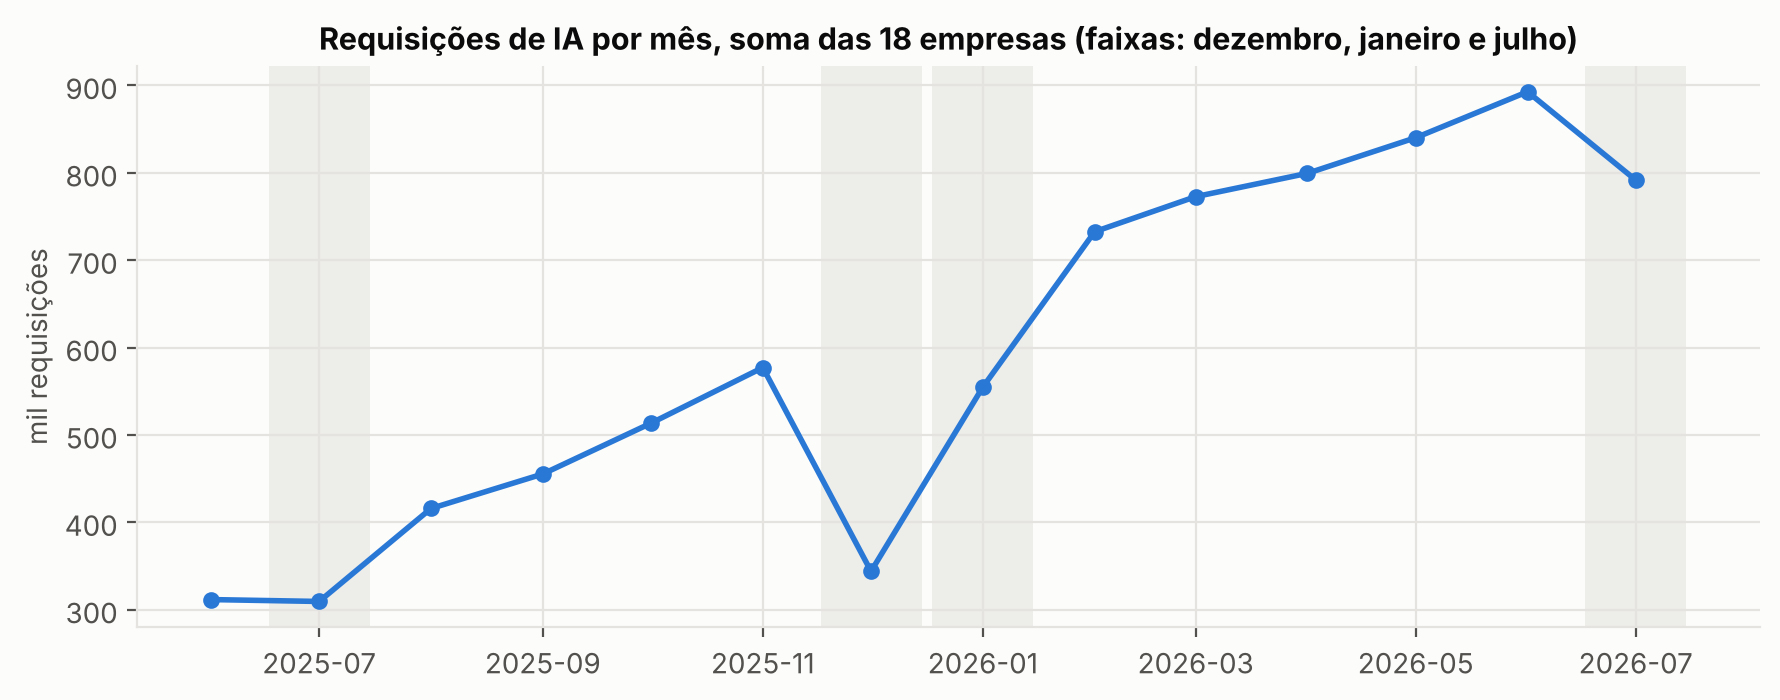

In [3]:
total = demanda.sum()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot([p.to_timestamp() for p in MESES], total / 1e3, color=AZUL, marker='o', ms=5)
for p in MESES:
    if p.month in FERIAS:
        ax.axvspan(p.to_timestamp() - pd.Timedelta(days=14), p.to_timestamp() + pd.Timedelta(days=14), color=GRADE, alpha=0.6, lw=0)
ax.set(title='Requisições de IA por mês, soma das 18 empresas (faixas: dezembro, janeiro e julho)', ylabel='mil requisições')
fig.tight_layout(); fig.savefig(FIG / 'fig1_demanda_total.png', dpi=150); plt.show()

A série total sobe de forma quase linear e cai nos meses de férias: dezembro de 2025, janeiro e julho de 2026. Esse padrão define os modelos candidatos: **tendência + efeito de calendário**.

## 4. Modelos candidatos

| Modelo | Como prevê | Por que testar |
|---|---|---|
| **Ingênuo** | Repete o último mês | Referência mínima: um modelo útil tem de superá-lo |
| **Média móvel de 3 meses** | Média dos três últimos meses | Suaviza ruído, mas não acompanha tendência |
| **Holt amortecido** | Suavização exponencial com tendência amortecida, em log | Clássico para séries curtas com tendência |
| **Tendência + férias** | Regressão linear por empresa: tempo + indicador de mês de férias | Captura tendência e calendário com poucos parâmetros |
| **Tendência × fatores comuns** | Tendência linear por empresa multiplicada por um fator de calendário (dez, jan, jul) **comum a todas as empresas** | Cada empresa viu um único dezembro. Estimar o fator com as 18 empresas juntas é mais estável |
| **Tendência log × fatores comuns** | Igual à anterior, mas a tendência é uma reta no **log** da demanda: crescimento **proporcional** (a mesma taxa % por mês), em vez de **aditivo** (o mesmo número de requisições a mais por mês) | Em seis meses, as duas hipóteses dão previsões muito diferentes. O backtest e os resíduos (seção 5.4) decidem entre elas |
| **Gradient boosting global** | Um só modelo de árvores para todas as empresas, prevendo a variação em relação ao último mês a partir das defasagens, do calendário e do horizonte | Abordagem de aprendizado de máquina para séries, para comparar com os modelos estatísticos |

**Fator de calendário comum.** Para cada mês de férias, o fator é a mediana, entre as empresas, da razão entre o valor observado e a tendência da própria empresa. A conta é repetida três vezes, reestimando a tendência sem o efeito das férias. Na versão em log, a tendência usada nessa conta também é a do log. Só entram meses de férias **já observados até a origem** da previsão: antes do primeiro janeiro da base, o fator de janeiro é 1.

**Séries curtas.** Uma tendência estimada com menos de 6 meses extrapola qualquer oscilação da adoção. A TextilNorte, por exemplo, tem 4 meses, com pico em maio e queda depois. Nesses casos, os modelos de tendência usam o **nível médio dos últimos 3 meses**, sem o efeito do calendário, multiplicado pelo calendário dos meses previstos.

In [4]:
TENDENCIAS = ('Tendência + férias', 'Tendência × fatores comuns', 'Tendência log × fatores comuns')

def calendario(periodos):
    return np.array([[int(p.month == m) for m in FERIAS] for p in periodos])

def ajustar_tendencia(t, v, log=False):
    """Reta em v (crescimento aditivo: o mesmo número de requisições a mais por mês)
    ou reta em log(v) (crescimento proporcional: a mesma taxa % por mês)."""
    return np.polyfit(t, np.log(np.maximum(v, 1)), 1) if log else np.polyfit(t, v, 1)

def avaliar_tendencia(b, t, log=False):
    return np.exp(np.polyval(b, t)) if log else np.polyval(b, t)

def fatores_comuns(series, origem, log=False):
    """Fatores multiplicativos de dez, jan e jul estimados com todas as séries até a origem."""
    F = np.ones(3)
    for _ in range(3):
        razoes = {m: [] for m in range(3)}
        for s in series:
            s = s[s.index <= origem]
            if len(s) < 4:
                continue
            t = np.arange(len(s)); d = calendario(s.index)
            ajuste = s.values / np.exp(d @ np.log(F))
            tend = avaliar_tendencia(ajustar_tendencia(t, ajuste, log), t, log)
            for j in range(3):
                for i in np.where(d[:, j] == 1)[0]:
                    if tend[i] > 0:
                        razoes[j].append(s.values[i] / tend[i])
        F = np.array([np.median(razoes[j]) if razoes[j] else 1.0 for j in range(3)])
    return F

def prever(s, h, metodo, F=None):
    """s: série de uma empresa (a partir do início do uso) até a origem; devolve h previsões."""
    y = s.values.astype(float); fut = pd.period_range(s.index[-1] + 1, periods=h, freq='M')
    t, tf = np.arange(len(y)), np.arange(len(y), len(y) + h)
    if metodo == 'Ingênuo' or (len(y) < 4 and metodo != 'Média móvel 3m'):
        return np.repeat(y[-1], h)
    if metodo == 'Média móvel 3m':
        return np.repeat(y[-3:].mean(), h)
    if metodo == 'Holt amortecido':
        m = ExponentialSmoothing(np.log(np.maximum(y, 1)), trend='add', damped_trend=True, initialization_method='estimated').fit()
        return np.exp(m.forecast(h))
    if metodo in TENDENCIAS and len(y) < MIN_TENDENCIA:
        # histórico curto demais para uma tendência: nível dos últimos 3 meses, sem o efeito do calendário, vezes o calendário futuro
        Fu = F if F is not None else np.ones(3)
        nivel = (y[-3:] / np.exp(calendario(s.index[-3:]) @ np.log(Fu))).mean()
        return nivel * np.exp(calendario(fut) @ np.log(Fu))
    if metodo == 'Tendência + férias':
        fer = np.isin([p.month for p in s.index], FERIAS).astype(int)
        X = np.c_[np.ones_like(t), t] if fer.sum() == 0 else np.c_[np.ones_like(t), t, fer]
        b = np.linalg.lstsq(X, y, rcond=None)[0]
        ff = np.isin([p.month for p in fut], FERIAS).astype(int)
        Xf = np.c_[np.ones(h), tf] if fer.sum() == 0 else np.c_[np.ones(h), tf, ff]
        return np.maximum(Xf @ b, 0)
    if metodo in ('Tendência × fatores comuns', 'Tendência log × fatores comuns'):
        log = metodo == 'Tendência log × fatores comuns'
        ajuste = y / np.exp(calendario(s.index) @ np.log(F))
        b = ajustar_tendencia(t, ajuste, log)
        return np.maximum(avaliar_tendencia(b, tf, log), 0) * np.exp(calendario(fut) @ np.log(F))
    raise ValueError(metodo)

**Gradient boosting global.** Cada linha de treino é uma empresa num mês *t* com horizonte *k* de 1 a 3. O alvo é log(*y*<sub>t+k</sub> / *y*<sub>t</sub>). As variáveis são:

- as variações recentes: log(*y*<sub>t</sub>/*y*<sub>t−1</sub>), log(*y*<sub>t</sub>/*y*<sub>t−2</sub>) e log(*y*<sub>t</sub>/*y*<sub>t−3</sub>);
- o horizonte *k*;
- os indicadores de férias do mês *t* e do mês *t*+*k*;
- os meses desde o início do uso.

Só entram linhas cujo alvo já era conhecido na origem.

In [5]:
def linhas_globais(series_dict, ate):
    L = []
    for c, s in series_dict.items():
        s = s[s.index <= ate]
        v = np.maximum(s.values.astype(float), 1)
        for i in range(3, len(s)):
            for k in range(1, H + 1):
                alvo = np.log(v[i + k] / v[i]) if i + k < len(s) else np.nan
                p_alvo = s.index[i] + k
                L.append(dict(empresa=c, origem=s.index[i], k=k, alvo=alvo,
                              d1=np.log(v[i] / v[i - 1]), d2=np.log(v[i] / v[i - 2]), d3=np.log(v[i] / v[i - 3]),
                              fer_t=int(s.index[i].month in FERIAS), fer_alvo=int(p_alvo.month in FERIAS),
                              dez_alvo=int(p_alvo.month == 12), idade=i, nivel=v[i]))
    return pd.DataFrame(L)

VARS_GB = ['k', 'd1', 'd2', 'd3', 'fer_t', 'fer_alvo', 'dez_alvo', 'idade']

def prever_global(series_dict, origem):
    """Treina com o que se conhecia na origem e prevê h = 1..H para cada empresa."""
    L = linhas_globais(series_dict, origem)
    tr = L[L.alvo.notna()]
    gb = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_leaf_nodes=8, min_samples_leaf=10, random_state=SEED)
    gb.fit(tr[VARS_GB], tr.alvo)
    ult = L[L.origem == origem]
    out = {}
    for c, g in ult.groupby('empresa'):
        g = g.sort_values('k')
        out[c] = g.nivel.values * np.exp(gb.predict(g[VARS_GB]))
    return out

## 5. Validação: backtest com origem móvel

A validação imita o uso real. Em cada **origem**, de dezembro de 2025 a junho de 2026, os modelos veem só os dados até aquele mês e preveem os 1 a 3 meses seguintes, que são comparados com o que aconteceu. Nenhum dado do futuro entra no ajuste.

**Seleção e confirmação separadas no tempo.** Escolher o modelo e medir o erro com as mesmas previsões deixa o erro otimista: o vencedor é, em parte, quem teve sorte naquelas origens. Por isso o backtest é dividido como seria na prática, com a escolha feita no fim de abril de 2026:

| Parte | Previsões | Para quê |
|---|---|---|
| **Seleção** | Origens de dez/2025 a mar/2026, só as com mês-alvo até abr/2026 | Escolher o modelo e calibrar a faixa de 80% |
| **Confirmação** | Origens de abr a jun/2026 (alvos de mai a jul/2026) | Medir o erro e a cobertura da faixa do modelo já escolhido. Nenhuma escolha usa estas previsões |
| Fora das duas | Origens de fev e mar/2026 com alvo em mai ou jun/2026 | Não entram: o alvo cai no período da confirmação, que a seleção não pode ver |

**Métricas**
- **WAPE (principal):** erro absoluto total dividido pela demanda total. É uma porcentagem e não explode em séries com valores baixos, mas pesa cada empresa pelo seu volume.
- **sMAPE:** erro percentual simétrico, médio por previsão. Dá o mesmo peso a cada empresa, grande ou pequena.
- **MAE:** erro médio em requisições.
- **Viés:** soma dos erros sobre a soma do real. Positivo quer dizer que o modelo superestima.

A tabela abaixo conta as previsões de cada modelo em cada parte.

In [6]:
METODOS = ['Ingênuo', 'Média móvel 3m', 'Holt amortecido', 'Tendência + férias', 'Tendência × fatores comuns',
           'Tendência log × fatores comuns', 'Gradient boosting global']
PARTES = ['seleção', 'confirmação', 'fora: alvo no período da confirmação']

def series_validas(tabela):
    return {c: tabela.loc[c][tabela.loc[c].index >= inicio_serie(tabela.loc[c])] for c in tabela.index if tabela.loc[c].sum() > 0}

def backtest(tabela, metodos=METODOS):
    series = series_validas(tabela)
    linhas = []
    for o in ORIGENS:
        F = {log: fatores_comuns(list(series.values()), o, log=log) for log in (False, True)}
        glob = prever_global(series, o) if 'Gradient boosting global' in metodos else {}
        for c, s in series.items():
            hist = s[s.index <= o]
            if len(hist) < 3:
                continue
            for metodo in metodos:
                Fm = F[metodo == 'Tendência log × fatores comuns']
                f = glob.get(c) if metodo == 'Gradient boosting global' else prever(hist, H, metodo, Fm)
                if f is None:
                    f = prever(hist, H, 'Ingênuo')
                for k in range(1, H + 1):
                    alvo = o + k
                    if alvo > MESES[-1]:
                        continue
                    linhas.append(dict(origem=str(o), empresa=c, metodo=metodo, h=k, mes=str(alvo), real=s[alvo], previsto=float(f[k - 1])))
    bt = pd.DataFrame(linhas)
    o, a = pd.PeriodIndex(bt.origem, freq='M'), pd.PeriodIndex(bt.mes, freq='M')
    bt['parte'] = np.select([a <= FIM_SELECAO, o >= FIM_SELECAO], PARTES[:2], PARTES[2])
    return bt

def resumo_erros(bt):
    def m(g):
        e = g.previsto - g.real
        return pd.Series({'WAPE': e.abs().sum() / g.real.sum(), 'MAE': e.abs().mean(),
                          'sMAPE': (2 * e.abs() / (g.real.abs() + g.previsto.abs()).replace(0, np.nan)).mean(),
                          'viés': e.sum() / g.real.sum(), 'n': len(g)})
    por_h = bt.groupby(['metodo', 'h']).apply(m, include_groups=False).unstack('h')
    geral = bt.groupby('metodo').apply(m, include_groups=False)
    return por_h, geral

def tabela_metricas(bt):
    por_h, geral = resumo_erros(bt)
    return pd.concat({**{f'WAPE h={k}': por_h['WAPE'][k] for k in range(1, H + 1)},
                      'WAPE geral': geral['WAPE'], 'sMAPE geral': geral['sMAPE'], 'viés': geral['viés'],
                      'MAE': geral['MAE'], 'previsões': geral['n']}, axis=1)

bt_dem = backtest(demanda)
bt_dem.to_csv(SAIDA / 'backtest_demanda.csv', index=False)
pd.crosstab(bt_dem.metodo, bt_dem.parte, margins=True, margins_name='total').loc[METODOS + ['total'], PARTES + ['total']]

parte,seleção,confirmação,fora: alvo no período da confirmação,total
metodo,,,,
Ingênuo,118,100,44,262
Média móvel 3m,118,100,44,262
Holt amortecido,118,100,44,262
Tendência + férias,118,100,44,262
Tendência × fatores comuns,118,100,44,262
Tendência log × fatores comuns,118,100,44,262
Gradient boosting global,118,100,44,262
total,826,700,308,1834


### 5.1 O que entra no backtest: de 378 para 262 previsões por modelo

A grade completa tem 7 origens × 18 empresas × 3 horizontes = 378 previsões por modelo. Duas regras descartam previsões, as mesmas para todos os modelos, que assim são comparados nas mesmas 262:

- **Alvo depois de jul/2026.** O último mês observado é julho de 2026. Da origem de mai/2026, o horizonte de 3 meses cai em agosto; da origem de jun/2026, os de 2 e 3 meses caem em agosto e setembro. São 3 previsões por empresa.
- **Menos de 3 meses de uso na origem.** Com 1 ou 2 meses de série não há o que ajustar, e a previsão seria repetir o começo da adoção. Isso atinge as seis empresas que começaram a usar IA a partir de nov/2025.

In [7]:
series_dem = series_validas(demanda)
grade = []
for o in ORIGENS:
    for c in demanda.index:
        n_hist = int((series_dem[c].index <= o).sum()) if c in series_dem else 0
        for k in range(1, H + 1):
            alvo = o + k
            motivo = ('descartada: alvo depois de jul/2026 (ainda não observado)' if alvo > MESES[-1] else
                      'descartada: menos de 3 meses de uso na origem' if n_hist < 3 else 'avaliada')
            grade.append(dict(origem=str(o), empresa=c, h=k, mes=str(alvo), meses_de_uso_na_origem=n_hist, motivo=motivo))
grade = pd.DataFrame(grade)
avaliadas = (grade.motivo == 'avaliada').sum()
assert (bt_dem.groupby('metodo').size() == avaliadas).all(), 'todos os modelos são avaliados nas mesmas previsões'
print(f'Grade completa: {len(ORIGENS)} origens × {len(demanda)} empresas × {H} horizontes = {len(grade)} previsões por modelo')
display(grade.motivo.value_counts().rename('previsões').to_frame())

curtas = grade[grade.motivo == 'descartada: menos de 3 meses de uso na origem']
curtas = (curtas.groupby('empresa').agg(previsoes_descartadas=('h', 'size'), origens_afetadas=('origem', lambda x: f'{x.min()} a {x.max()}'))
          .join(diag[['empresa', 'inicio_do_uso']]))
display(curtas)
print('Previsões avaliadas por horizonte:', grade[grade.motivo == 'avaliada'].groupby('h').size().to_dict())

Grade completa: 7 origens × 18 empresas × 3 horizontes = 378 previsões por modelo


,previsões
motivo,
avaliada,262
descartada: menos de 3 meses de uso na origem,62
descartada: alvo depois de jul/2026 (ainda não observado),54


,previsoes_descartadas,origens_afetadas,empresa,inicio_do_uso
empresa,,,,
C05,6,2025-12 a 2026-01,ByteFlow Engenharia de Software,2025-12
C07,12,2025-12 a 2026-03,Capital Sul Investimentos,2026-02
C09,3,2025-12 a 2025-12,Metalurgica Vale Forte,2025-11
C11,17,2025-12 a 2026-05,TextilNorte Manufatura,2026-04
C13,9,2025-12 a 2026-02,Lojas Formosa,2026-01
C16,15,2025-12 a 2026-04,ServPro Facilities,2026-03


Previsões avaliadas por horizonte: {1: 105, 2: 87, 3: 70}


- **54 previsões** têm alvo depois de jul/2026 (3 por empresa) e **62** caem em séries com menos de 3 meses de uso. Sobram **262**: 105 a 1 mês, 87 a 2 meses e 70 a 3 meses.
- Os descartes por histórico curto se concentram em TextilNorte (17), ServPro (15) e Capital Sul (12), que começaram em 2026. Por isso as três têm poucas previsões avaliadas e erros instáveis.
- Com 3 meses de uso, os modelos de tendência ainda não ajustam uma reta e repetem o último mês. Com 4 e 5 meses, usam o nível recente vezes o calendário (regras da seção 4).
- Das 262, **118** ficam na seleção, **100** na confirmação e **44** fora das duas.

### 5.2 Seleção: qual modelo usar (alvos até abr/2026)

Cada modelo é avaliado nas 118 previsões da seleção, e o escolhido é o de menor WAPE geral. Nada da confirmação entra nesta conta.

In [8]:
sel_bt = bt_dem[bt_dem.parte == 'seleção']
conf_bt = bt_dem[bt_dem.parte == 'confirmação']
tab_sel = tabela_metricas(sel_bt).loc[METODOS].sort_values('WAPE geral')
ESCOLHIDO = tab_sel.index[0]
print(f'Modelo escolhido na seleção (menor WAPE, alvos até {FIM_SELECAO}): {ESCOLHIDO}')
tab_sel.round(3)

Modelo escolhido na seleção (menor WAPE, alvos até 2026-04): Tendência × fatores comuns


,WAPE h=1,WAPE h=2,WAPE h=3,WAPE geral,sMAPE geral,viés,MAE,previsões
metodo,,,,,,,,
Tendência × fatores comuns,0.075,0.074,0.091,0.078,0.140,-0.041,4327.209,118.0
Tendência log × fatores comuns,0.091,0.077,0.076,0.083,0.144,0.035,4589.745,118.0
Tendência + férias,0.095,0.106,0.139,0.109,0.164,-0.096,6022.205,118.0
Holt amortecido,0.171,0.269,0.360,0.248,0.345,-0.244,13736.599,118.0
Ingênuo,0.167,0.290,0.420,0.267,0.346,-0.260,14799.492,118.0
Gradient boosting global,0.235,0.270,0.374,0.279,0.366,-0.207,15464.012,118.0
Média móvel 3m,0.222,0.329,0.365,0.292,0.350,-0.291,16153.068,118.0


- **Tendência × fatores comuns** tem o menor erro: 7,8% de WAPE (7,5%, 7,4% e 9,1% de 1 a 3 meses), com viés de −4,1%.
- **A versão em log** fica perto, com 8,3%. A seleção sozinha não decide entre crescimento aditivo e proporcional. A confirmação e os resíduos decidem (seções 5.3 e 5.4).
- **Os modelos sem calendário** (ingênuo, média móvel e Holt) erram de 25% a 29%. A seleção cobre dezembro e janeiro, e eles não sabem que esses meses caem.
- **O gradient boosting global** (27,9%) também perde. Com poucos meses por empresa, falta histórico para aprender a dinâmica a partir das defasagens, e os modelos com estrutura explícita (tendência e calendário) levam vantagem.

### 5.3 Confirmação: quanto o modelo escolhido erra (origens de abr a jun/2026)

As 100 previsões da confirmação foram feitas de abr a jun/2026, para mai a jul/2026, e não participaram de nenhuma escolha. A tabela mantém a ordem da seleção.

In [9]:
tab_conf = tabela_metricas(conf_bt).loc[tab_sel.index]     # mesma ordem da seleção: nada aqui muda a escolha
pd.concat({'seleção': tab_sel, 'confirmação': tab_conf}, names=['parte', 'metodo']).to_csv(SAIDA / 'metricas_backtest_demanda.csv')
print(f'{ESCOLHIDO} na confirmação: WAPE {tab_conf.loc[ESCOLHIDO, "WAPE geral"]:.1%}, sMAPE {tab_conf.loc[ESCOLHIDO, "sMAPE geral"]:.1%}, '
      f'viés {tab_conf.loc[ESCOLHIDO, "viés"]:+.1%} | ingênuo: WAPE {tab_conf.loc["Ingênuo", "WAPE geral"]:.1%}')
tab_conf.round(3)

Tendência × fatores comuns na confirmação: WAPE 4.0%, sMAPE 7.3%, viés +1.8% | ingênuo: WAPE 7.9%


,WAPE h=1,WAPE h=2,WAPE h=3,WAPE geral,sMAPE geral,viés,MAE,previsões
metodo,,,,,,,,
Tendência × fatores comuns,0.039,0.044,0.038,0.040,0.073,0.018,2020.713,100.0
Tendência log × fatores comuns,0.071,0.088,0.108,0.083,0.094,0.074,4124.755,100.0
Tendência + férias,0.039,0.050,0.046,0.044,0.093,-0.025,2205.190,100.0
Holt amortecido,0.096,0.134,0.231,0.130,0.148,0.110,6497.526,100.0
Ingênuo,0.086,0.092,0.027,0.079,0.100,-0.006,3919.960,100.0
Gradient boosting global,0.060,0.068,0.048,0.060,0.103,0.044,3019.816,100.0
Média móvel 3m,0.091,0.095,0.065,0.088,0.115,-0.048,4411.580,100.0


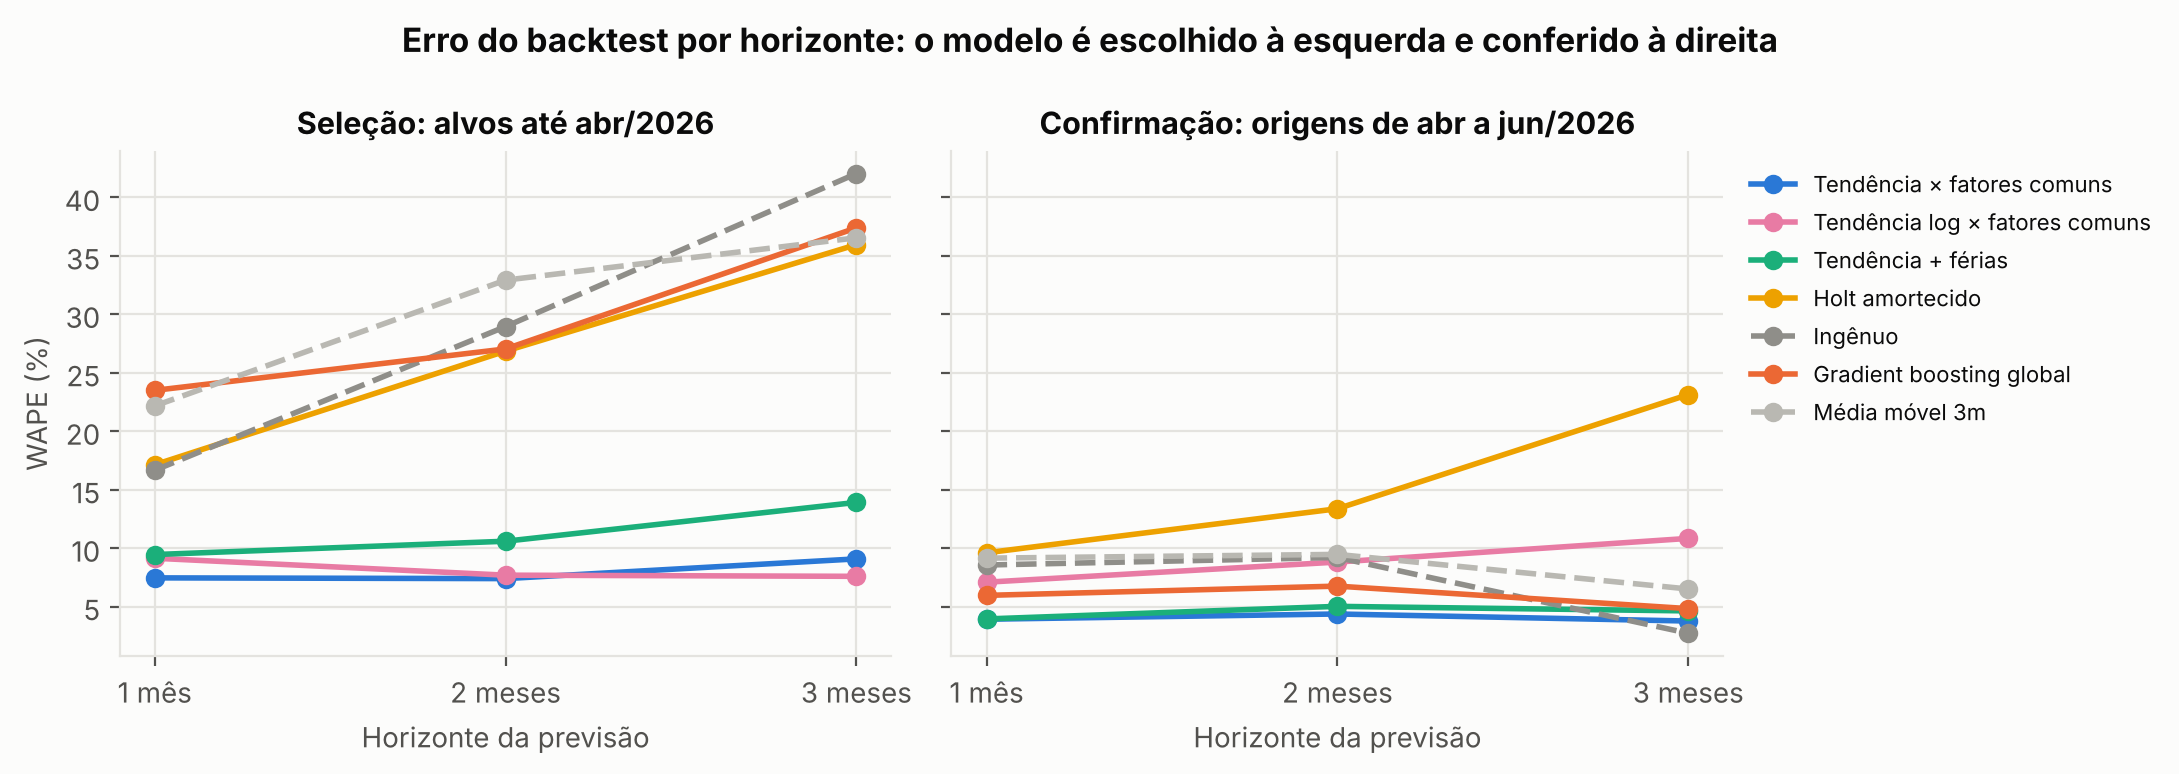

In [10]:
cores = {m: c for m, c in zip(METODOS, [CINZA, '#b9b8b2', AMARELO, VERDE, AZUL, MAGENTA, LARANJA])}
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
x = np.arange(1, H + 1)
for ax, (titulo, tab) in zip(eixos, [('Seleção: alvos até abr/2026', tab_sel), ('Confirmação: origens de abr a jun/2026', tab_conf)]):
    for m in tab_sel.index:
        ax.plot(x, tab.loc[m, [f'WAPE h={k}' for k in x]].values * 100, marker='o', ms=6, color=cores[m], label=m,
                ls='--' if m in ('Ingênuo', 'Média móvel 3m') else '-')
    ax.set_xticks(x, ['1 mês', '2 meses', '3 meses'])
    ax.set(title=titulo, xlabel='Horizonte da previsão')
eixos[0].set_ylabel('WAPE (%)')
eixos[1].legend(loc='upper left', fontsize=8, ncol=1, bbox_to_anchor=(1.01, 1))
fig.suptitle('Erro do backtest por horizonte: o modelo é escolhido à esquerda e conferido à direita', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / 'fig2_backtest_horizonte.png', dpi=150); plt.show()

- **O modelo escolhido se confirma:** WAPE de **4,0%** (3,9%, 4,4% e 3,8% de 1 a 3 meses), **sMAPE de 7,3%** e viés de +1,8%. É metade do erro do ingênuo (7,9%).
- **A confirmação é um período fácil.** De maio a julho há um só mês de férias (julho) e nenhum dezembro ou janeiro, e todos os modelos erram menos que na seleção. O ingênuo erra só 2,7% a 3 meses, mas isso vem de uma única origem (abr → jul), em que três meses de crescimento e a queda de julho se compensam. Para os meses de férias previstos (dez/2026 e jan/2027), a referência mais honesta é o erro em janeiro de 2026 (13,9%, abaixo).
- **A versão em log piora fora da amostra:** 8,3% de WAPE e viés de **+7,4%**. Ela superestima porque projeta crescimento a taxa constante. É a primeira evidência de que o crescimento é aditivo (seção 5.4).

#### Erro por empresa e por mês

O WAPE soma os erros de todas as empresas e divide pela demanda total, então pesa cada uma pelo seu volume. A NexoCode sozinha é quase metade da demanda e domina o número. Como o alerta de orçamento é por centro de custo, o que importa para o produto é o erro de cada empresa, não o do total.

A tabela traz, por empresa: o peso no WAPE da confirmação, o WAPE na seleção e na confirmação, o viés na confirmação e o ingênuo para comparação.

In [11]:
wape = lambda g: (g.previsto - g.real).abs().sum() / g.real.sum()
smape = lambda g: (2 * (g.previsto - g.real).abs() / (g.real.abs() + g.previsto.abs()).replace(0, np.nan)).mean()
esc = bt_dem[bt_dem.metodo == ESCOLHIDO]
esc_conf, esc_sel = esc[esc.parte == 'confirmação'], esc[esc.parte == 'seleção']
ing_conf = bt_dem[(bt_dem.metodo == 'Ingênuo') & (bt_dem.parte == 'confirmação')]
por_empresa = pd.DataFrame({
    'empresa': comp.set_index('company_id').company_name,
    'peso_no_WAPE': esc_conf.groupby('empresa').real.sum() / esc_conf.real.sum(),
    'WAPE_selecao': esc_sel.groupby('empresa').apply(wape, include_groups=False),
    'WAPE_confirmacao': esc_conf.groupby('empresa').apply(wape, include_groups=False),
    'vies_confirmacao': esc_conf.groupby('empresa').apply(lambda g: (g.previsto - g.real).sum() / g.real.sum(), include_groups=False),
    'WAPE_ingenuo_confirmacao': ing_conf.groupby('empresa').apply(wape, include_groups=False),
    'previsoes_confirmacao': esc_conf.groupby('empresa').size(),
}).sort_values('peso_no_WAPE', ascending=False)
por_empresa.index.name = 'company_id'
por_empresa.to_csv(SAIDA / 'erro_por_empresa.csv')

grandes = por_empresa.index[por_empresa.peso_no_WAPE >= 0.05]
print(f'Confirmação, {ESCOLHIDO}:')
print(f'  WAPE total {wape(esc_conf):.1%} | sem a NexoCode {wape(esc_conf[esc_conf.empresa != "C01"]):.1%} | '
      f'NexoCode = {por_empresa.loc["C01", "peso_no_WAPE"]:.0%} do volume')
print(f'  sMAPE {smape(esc_conf):.1%} | WAPE mediano por empresa {por_empresa.WAPE_confirmacao.median():.1%}')
print(f'  {len(grandes)} empresas com ≥ 5% do volume ({por_empresa.loc[grandes, "peso_no_WAPE"].sum():.0%} do total): WAPE de '
      f'{por_empresa.loc[grandes, "WAPE_confirmacao"].min():.1%} a {por_empresa.loc[grandes, "WAPE_confirmacao"].max():.1%}')
outras = por_empresa.drop(grandes)
print(f'  outras {len(outras)} empresas ({outras.peso_no_WAPE.sum():.0%} do volume): WAPE de '
      f'{outras.WAPE_confirmacao.min():.1%} a {outras.WAPE_confirmacao.max():.1%}, mediana {outras.WAPE_confirmacao.median():.1%}')

por_mes = pd.concat({ESCOLHIDO: esc.groupby('mes').apply(wape, include_groups=False),
                     'Ingênuo': bt_dem[bt_dem.metodo == 'Ingênuo'].groupby('mes').apply(wape, include_groups=False)}, axis=1)
por_mes['parte'] = np.where(pd.PeriodIndex(por_mes.index, freq='M') <= FIM_SELECAO, 'seleção', 'confirmação')
por_mes.to_csv(SAIDA / 'erro_por_mes.csv')
display(por_empresa.round(3))
por_mes.round(3).T

Confirmação, Tendência × fatores comuns:
  WAPE total 4.0% | sem a NexoCode 5.8% | NexoCode = 48% do volume
  sMAPE 7.3% | WAPE mediano por empresa 5.8%
  3 empresas com ≥ 5% do volume (74% do total): WAPE de 2.2% a 6.7%
  outras 15 empresas (26% do volume): WAPE de 1.7% a 60.5%, mediana 5.9%


,empresa,peso_no_WAPE,WAPE_selecao,WAPE_confirmacao,vies_confirmacao,WAPE_ingenuo_confirmacao,previsoes_confirmacao
company_id,,,,,,,
C01,NexoCode Solucoes,0.475,0.073,0.022,0.006,0.085,6
C02,Vortice Software,0.187,0.043,0.050,0.050,0.048,6
C04,Cronos Tech Labs,0.081,0.081,0.067,0.067,0.056,6
C06,Banco Alterosa S.A.,0.036,0.064,0.018,-0.010,0.071,6
C18,Estrela Marketing Digital,0.034,0.088,0.053,-0.011,0.105,6
C14,MercadoPrime E-commerce,0.033,0.126,0.056,-0.019,0.027,6
C15,Prisma Consultoria Empresarial,0.031,0.121,0.072,0.036,0.112,6
C03,Piloto Digital Sistemas,0.030,0.121,0.092,0.012,0.174,6
C17,Ideia Fresca Marketing,0.024,0.099,0.028,-0.017,0.063,6


mes,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
Tendência × fatores comuns,0.139,0.099,0.074,0.055,0.034,0.046,0.041
Ingênuo,0.378,0.381,0.292,0.149,0.1,0.107,0.077
parte,seleção,seleção,seleção,seleção,confirmação,confirmação,confirmação


- **O total esconde a heterogeneidade.** A NexoCode é 48% do volume e erra só 2,2%. Sem ela, o WAPE sobe de 4,0% para 5,8%. O sMAPE (7,3%) e o WAPE mediano por empresa (5,8%) descrevem melhor uma empresa típica.
- **Grandes:** as 3 empresas com pelo menos 5% do volume (NexoCode, Vortice e Cronos, 74% do total) erram de 2,2% a 6,7%. Vortice e Cronos são superestimadas (viés de +5,0% e +6,7%), e nelas o ingênuo empata ou vence: o crescimento das duas desacelerou (seção 5.4).
- **Pequenas:** as outras 15 erram de 1,7% a 60,5%, com mediana de 5,9%. Cinco passam de 10%: ByteFlow (11,7%), Capital Sul (16,4%), Fincredi (16,6%), ServPro (18,3%) e TextilNorte (60,5%). Capital Sul, ServPro e TextilNorte começaram a usar IA em 2026. A TextilNorte tem uma só previsão na confirmação, em plena rampa de adoção, que nenhum método previu. ByteFlow e Fincredi somam 2% do volume, e a variação de poucos colaboradores pesa.
- **Por mês:** o maior erro é janeiro de 2026 (13,9%), o primeiro janeiro da base, cujo tamanho nenhum modelo podia conhecer. Depois, cai mês a mês: 9,9%, 7,4% e 5,5% de fevereiro a abril, e de 3,4% a 4,6% na confirmação.
- **Para o alerta por centro de custo**, a margem de erro relevante é a da empresa: de 2% a 7% nas grandes, e acima de 10% em cinco pequenas.

### 5.4 Diagnóstico dos resíduos: a tendência linear é adequada?

O modelo escolhido é, para cada empresa, uma regressão linear da demanda (sem o efeito do calendário) contra o tempo. Extrapolá-la supõe que o crescimento é **aditivo**: o mesmo número de requisições a mais por mês. A alternativa é crescimento **proporcional**, a mesma taxa % por mês, que é uma reta no log. A diferença pesa: na NexoCode, a primeira leva a 531 mil requisições em novembro; a segunda, a 648 mil (seção 6.1).

Para as 16 empresas com pelo menos 6 meses de uso, as duas versões são ajustadas com o histórico inteiro, e os resíduos de cada regressão são testados:

| Teste | O que indicaria problema |
|---|---|
| **Ljung-Box** (até 2 defasagens) e **Durbin-Watson** | Resíduos autocorrelacionados: o modelo deixa um padrão sem explicar, e os erros de meses seguidos se somam. O Durbin-Watson esperado é perto de 2; abaixo de 1,2 indica autocorrelação positiva |
| **Breusch-Pagan** contra o tempo | Heterocedasticidade: a variância do erro cresce ou cai ao longo da série |
| **Curvatura** (termo t² na regressão) | Forma de crescimento errada. Na versão linear, t² positivo indicaria crescimento proporcional. Na versão em log, t² negativo indica que a série cresce mais devagar que uma taxa constante, ou seja, de forma aditiva |

Com 6 a 14 meses por empresa, os testes têm pouco poder. A leitura é pelo conjunto das 16 empresas e pelo erro fora da amostra (seções 5.2 e 5.3), não por um p-valor isolado.

In [12]:
def ajuste_final(s, F, log):
    """Regressão da tendência com o histórico inteiro: v = a + b·t (linear) ou log(v) = a + b·t (log),
    com v = série sem o efeito do calendário. Devolve o valor ajustado mês a mês, os coeficientes e o modelo do statsmodels."""
    t = np.arange(len(s)); cal = np.exp(calendario(s.index) @ np.log(F))
    v = s.values / cal
    alvo = np.log(np.maximum(v, 1)) if log else v
    m = sm.OLS(alvo, sm.add_constant(t.astype(float))).fit()
    ajustado = (np.exp(m.fittedvalues) if log else m.fittedvalues) * cal
    return ajustado, m.params[::-1], m

F_lin = fatores_comuns(list(series_dem.values()), MESES[-1])
F_log = fatores_comuns(list(series_dem.values()), MESES[-1], log=True)
linhas, residuos = [], {}
for c, s in series_dem.items():
    if len(s) < MIN_TENDENCIA:
        continue                                           # sem tendência: o modelo usa o nível recente (seção 4)
    t = np.arange(len(s)).astype(float); X = sm.add_constant(t)
    linha = dict(company_id=c, empresa=comp.set_index('company_id').company_name[c], meses=len(s))
    for nome, log in (('linear', False), ('log', True)):
        ajustado, _, m = ajuste_final(s, F_log if log else F_lin, log)
        residuos[(c, nome)] = pd.Series(s.values / ajustado - 1, index=s.index)   # para o gráfico: (real − ajustado) / ajustado
        e = m.resid                                        # resíduo da própria regressão (em requisições ou em log)
        curv = sm.OLS(m.model.endog, np.c_[X, t ** 2]).fit()   # termo t² significativo = forma de crescimento errada
        linha.update({f'{nome}_erro_relativo': np.sqrt(np.mean(residuos[(c, nome)] ** 2)),
                      f'{nome}_autocorr_lag1': np.corrcoef(e[:-1], e[1:])[0, 1],
                      f'{nome}_durbin_watson': durbin_watson(e),
                      f'{nome}_ljung_box_p': acorr_ljungbox(e, lags=[2], return_df=True).lb_pvalue.iloc[0],
                      f'{nome}_breusch_pagan_p': het_breuschpagan(e, X)[1],
                      f'{nome}_curvatura_t': curv.tvalues[-1], f'{nome}_curvatura_p': curv.pvalues[-1]})
    linhas.append(linha)
diag_res = pd.DataFrame(linhas).set_index('company_id')
diag_res.to_csv(SAIDA / 'diagnostico_residuos.csv')

contagem = pd.DataFrame({nome: {
    'autocorrelação (Ljung-Box até 2 defasagens, p < 0,05)': (diag_res[f'{nome}_ljung_box_p'] < 0.05).sum(),
    'Durbin-Watson abaixo de 1,2 (autocorrelação positiva)': (diag_res[f'{nome}_durbin_watson'] < 1.2).sum(),
    'heterocedasticidade no tempo (Breusch-Pagan, p < 0,05)': (diag_res[f'{nome}_breusch_pagan_p'] < 0.05).sum(),
    'curvatura côncava (termo t² < 0, p < 0,05)': ((diag_res[f'{nome}_curvatura_p'] < 0.05) & (diag_res[f'{nome}_curvatura_t'] < 0)).sum(),
    'curvatura convexa (termo t² > 0, p < 0,05)': ((diag_res[f'{nome}_curvatura_p'] < 0.05) & (diag_res[f'{nome}_curvatura_t'] > 0)).sum(),
    'erro relativo mediano do ajuste': f"{diag_res[f'{nome}_erro_relativo'].median():.1%}"} for nome in ('linear', 'log')})
contagem.columns = ['Tendência linear (aditiva)', 'Tendência em log (proporcional)']
print(f'Empresas com pelo menos {MIN_TENDENCIA} meses de uso: {len(diag_res)} | a 5%, espera-se ~{0.05 * len(diag_res):.1f} rejeição por acaso em cada linha')
display(contagem)
cols = ['empresa', 'meses'] + [f'{n}_{m}' for n in ('linear', 'log') for m in ('erro_relativo', 'durbin_watson', 'ljung_box_p', 'breusch_pagan_p', 'curvatura_t', 'curvatura_p')]
diag_res[cols].round(3)

Empresas com pelo menos 6 meses de uso: 16 | a 5%, espera-se ~0.8 rejeição por acaso em cada linha


,Tendência linear (aditiva),Tendência em log (proporcional)
"autocorrelação (Ljung-Box até 2 defasagens, p < 0,05)",0,1
"Durbin-Watson abaixo de 1,2 (autocorrelação positiva)",1,2
"heterocedasticidade no tempo (Breusch-Pagan, p < 0,05)",2,1
"curvatura côncava (termo t² < 0, p < 0,05)",1,3
"curvatura convexa (termo t² > 0, p < 0,05)",0,0
erro relativo mediano do ajuste,6.3%,6.8%


,empresa,meses,linear_erro_relativo,linear_durbin_watson,linear_ljung_box_p,linear_breusch_pagan_p,linear_curvatura_t,linear_curvatura_p,log_erro_relativo,log_durbin_watson,log_ljung_box_p,log_breusch_pagan_p,log_curvatura_t,log_curvatura_p
company_id,,,,,,,,,,,,,,
C01,NexoCode Solucoes,14,0.028,2.735,0.204,0.865,0.163,0.873,0.040,1.796,0.913,0.682,-2.451,0.032
C02,Vortice Software,14,0.036,1.003,0.111,0.873,-3.334,0.007,0.061,0.553,0.026,0.325,-5.956,0.000
C03,Piloto Digital Sistemas,12,0.063,2.238,0.472,0.025,-1.194,0.263,0.080,1.090,0.688,0.447,-3.635,0.005
C04,Cronos Tech Labs,14,0.055,1.306,0.354,0.879,-1.178,0.263,0.056,1.704,0.323,0.172,-0.147,0.886
C05,ByteFlow Engenharia de Software,8,0.126,2.793,0.188,0.562,-0.571,0.593,0.128,2.632,0.201,0.795,-0.605,0.572
C06,Banco Alterosa S.A.,13,0.030,2.062,0.295,0.935,0.296,0.774,0.047,1.654,0.581,0.179,-1.679,0.124
C07,Capital Sul Investimentos,6,0.102,1.894,0.062,0.139,-0.581,0.602,0.106,1.941,0.060,0.248,-0.363,0.741
C08,Fincredi Solucoes Financeiras,11,0.119,1.921,0.746,0.025,0.085,0.934,0.131,1.947,0.810,0.629,-0.911,0.389
C09,Metalurgica Vale Forte,9,0.043,2.066,0.212,0.628,0.227,0.828,0.052,1.904,0.080,0.271,0.648,0.541


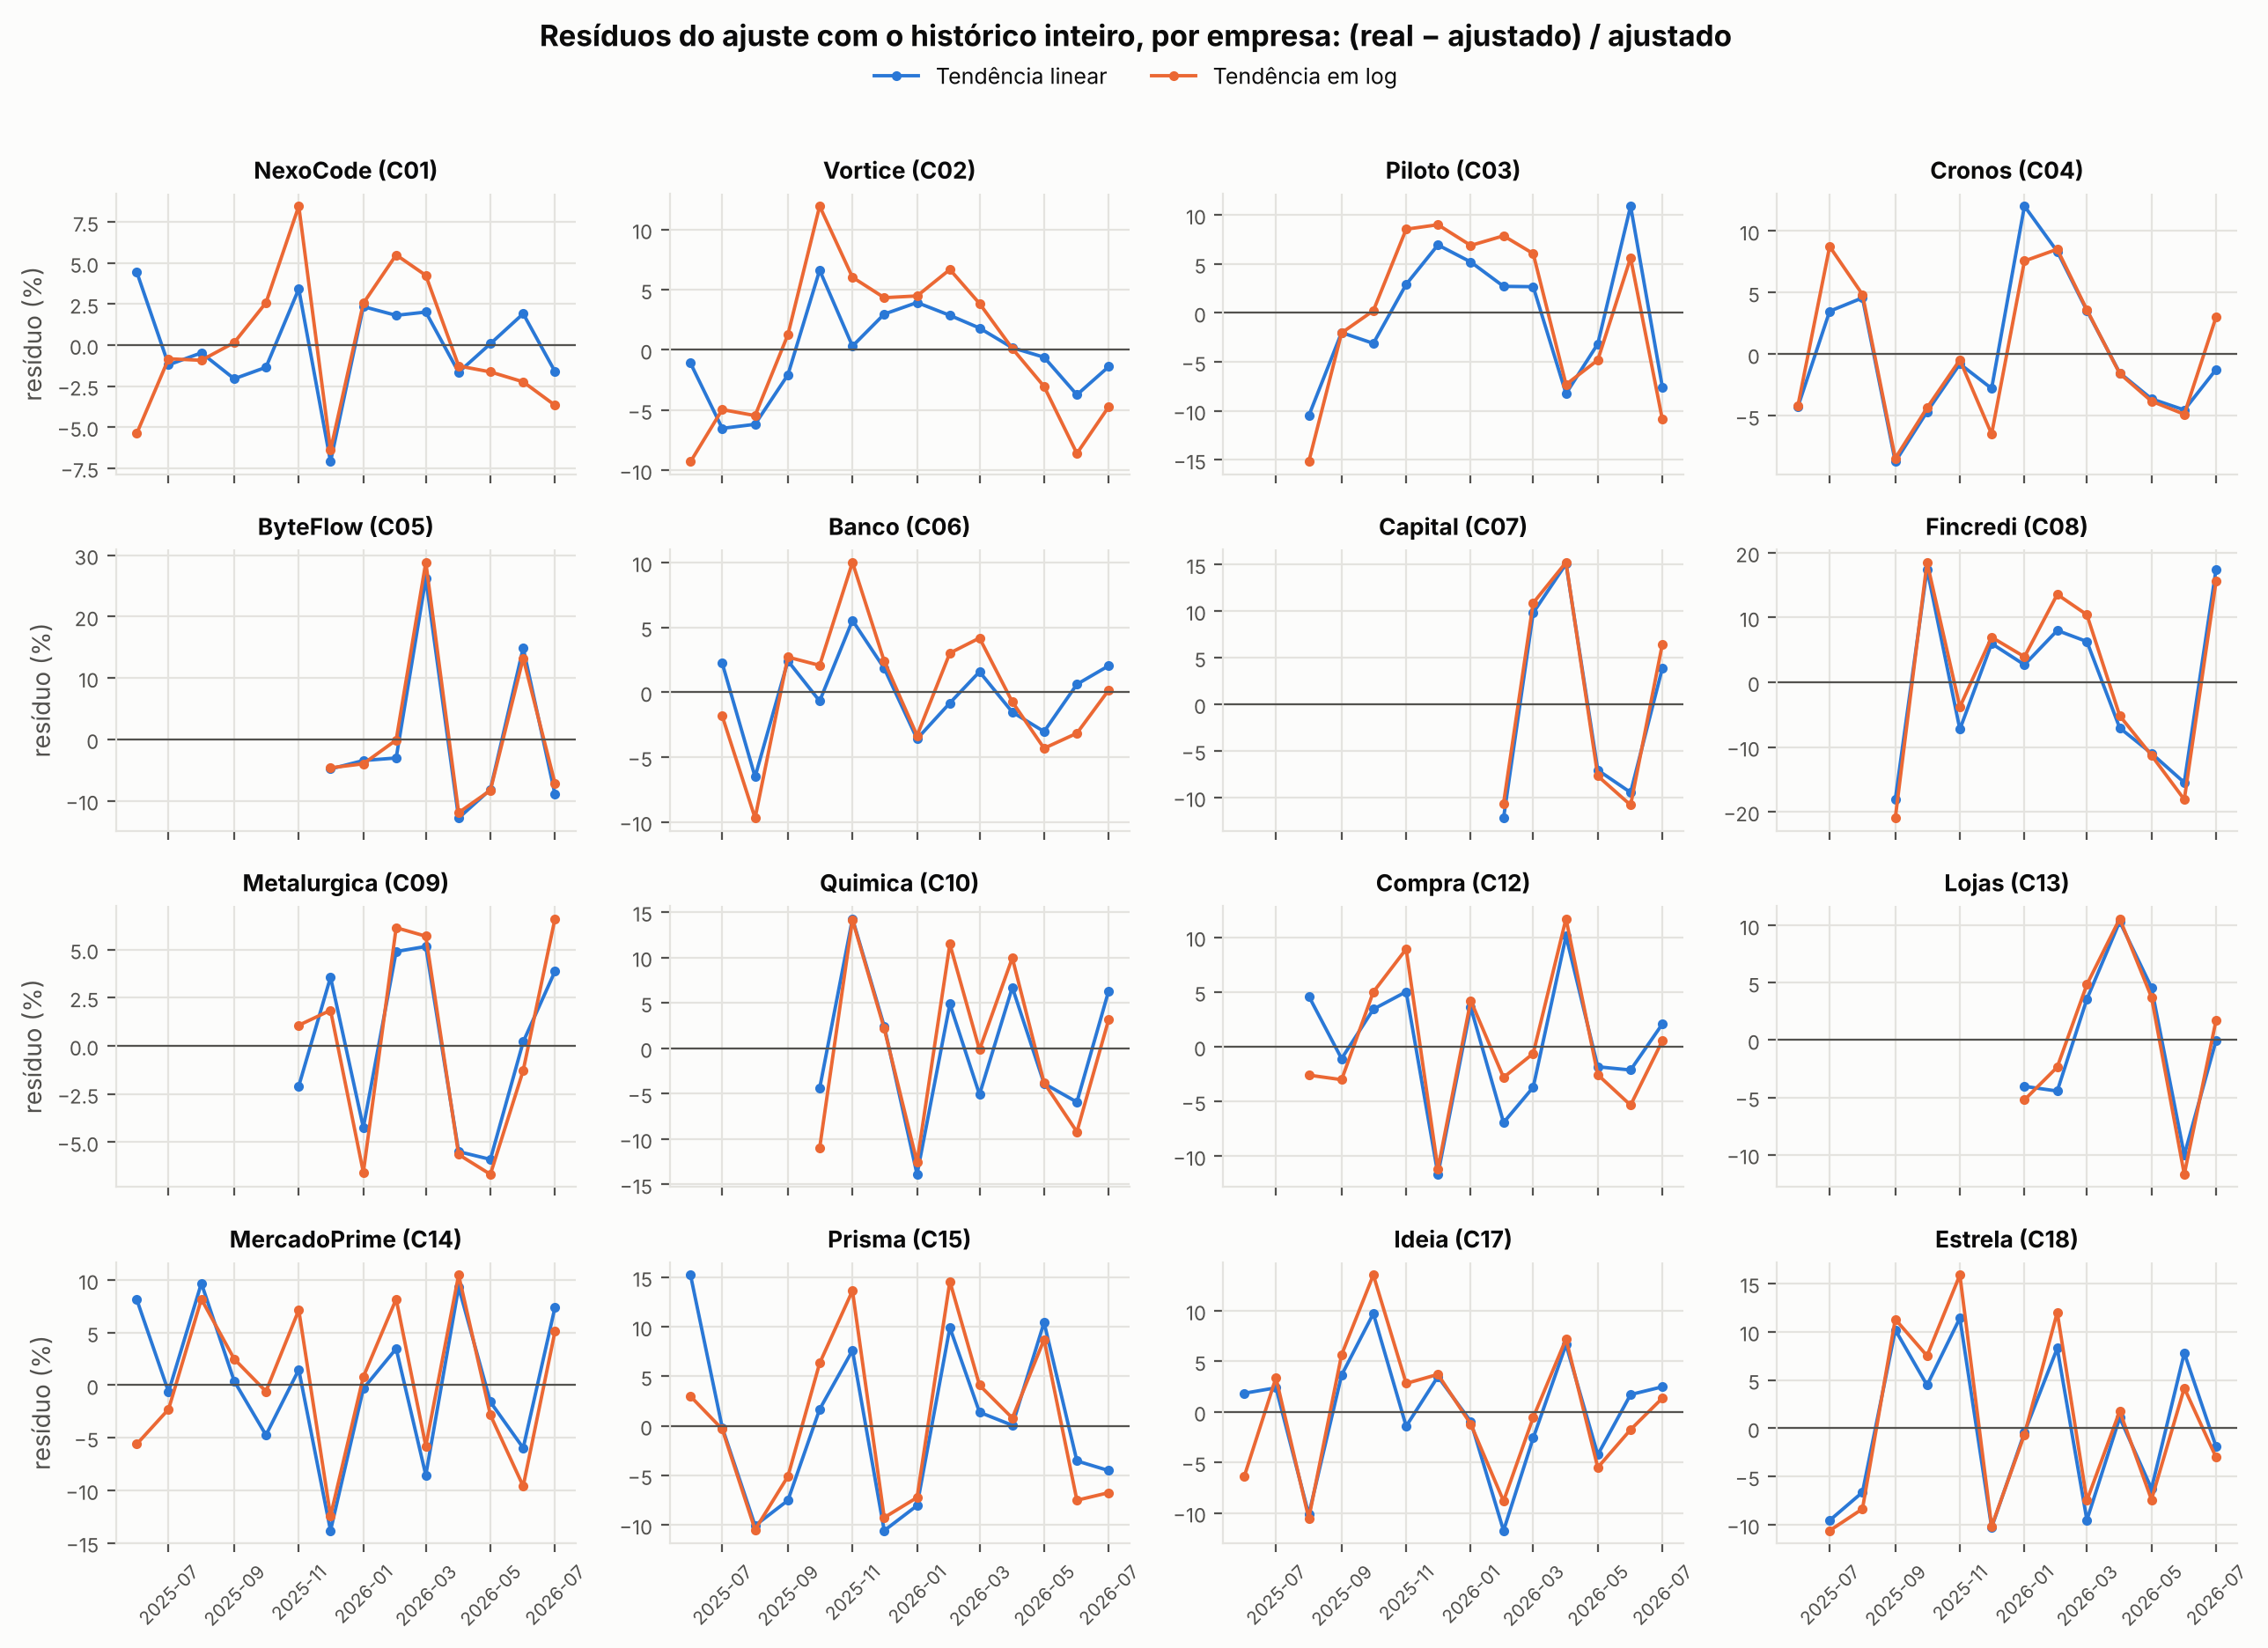

In [13]:
ordem = diag_res.index.tolist()
fig, eixos = plt.subplots(4, 4, figsize=(13, 9.5), sharex=True)
for ax, c in zip(eixos.flat, ordem):
    for nome, cor in (('linear', AZUL), ('log', LARANJA)):
        r = residuos[(c, nome)]
        ax.plot([p.to_timestamp() for p in r.index], r.values * 100, color=cor, marker='o', ms=3, lw=1.4,
                label='Tendência linear' if nome == 'linear' else 'Tendência em log')
    ax.axhline(0, color=TINTA2, lw=0.8)
    ax.set_title(f"{diag_res.loc[c, 'empresa'].split()[0]} ({c})", fontsize=9.5)
    ax.tick_params(axis='x', labelrotation=45, labelsize=7.5); ax.tick_params(axis='y', labelsize=8)
for ax in eixos.flat[len(ordem):]:
    ax.set_visible(False)
for ax in eixos[:, 0]:
    ax.set_ylabel('resíduo (%)')
fig.suptitle('Resíduos do ajuste com o histórico inteiro, por empresa: (real − ajustado) / ajustado', fontweight='bold')
fig.legend(*eixos.flat[0].get_legend_handles_labels(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0.965), fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(FIG / 'fig6_residuos_por_empresa.png', dpi=150); plt.show()

**Leitura**

- **A tendência linear passa nos testes.** Nenhuma empresa tem autocorrelação significativa no Ljung-Box, e os Durbin-Watson ficam entre 1,3 e 2,8, com uma exceção (Vortice, 1,0). A heterocedasticidade aparece em 2 das 16 (Piloto e Fincredi), perto da 0,8 esperada por acaso. Nenhuma empresa tem curvatura convexa, que seria o sinal de crescimento proporcional.
- **A versão em log falha onde mais importa.** Nas três empresas que crescem há mais tempo e mais rápido, NexoCode, Vortice e Piloto, o termo t² é negativo e significativo: no log, elas crescem cada vez mais devagar, que é o formato de um crescimento aditivo. Na Vortice, os resíduos no log também são autocorrelacionados (Durbin-Watson de 0,55).
- **O erro fora da amostra confirma.** Na confirmação, a versão em log superestima 7,4% e erra o dobro da linear (8,3% contra 4,0%). Por isso o modelo usa crescimento **aditivo**.
- **Ressalva: a Vortice desacelera.** Mesmo na versão linear, ela tem curvatura côncava (t² negativo, p = 0,007) e o Durbin-Watson mais baixo. Na confirmação, o modelo a superestima em 5,0%. A previsão de seis meses da Vortice tende a ficar alta, e a faixa de 80% não corrige um viés.
- **O erro relativo cai com o porte.** O resíduo relativo do ajuste é de 2,8% a 3,6% em NexoCode, Banco Alterosa e Vortice, e passa de 10% em ByteFlow (12,6%), Fincredi (11,9%) e Capital Sul (10,2%). Dentro de cada empresa a variância é estável; entre empresas, não. Por isso o erro é medido em termos relativos (WAPE e sMAPE) e a faixa de previsão é multiplicativa (no log).

### 5.5 Intervalos de previsão

A previsão vem com uma faixa de 80%. Ela sai dos **erros do próprio backtest**: o quantil 10% e o quantil 90% de log(real/previsto), por horizonte.

- **Calibração:** só com as previsões da seleção (alvos até abr/2026).
- **Teste:** cobertura nas previsões da confirmação. Se ficar perto de 80%, a regra é confiável.
- **Uso no futuro:** testada a regra, os quantis são recalculados com as 262 previsões das 7 origens, assim como o modelo é reajustado com os 14 meses. Essa faixa final só pode ser testada quando chegarem os próximos meses.

In [14]:
erro_log = lambda d: np.log(np.maximum(d.real, 1) / np.maximum(d.previsto, 1))
esc = esc.assign(erro_log=erro_log)
q_sel = esc[esc.parte == 'seleção'].groupby('h').erro_log.quantile([0.1, 0.9]).unstack()
aval = esc[esc.parte == 'confirmação'].join(q_sel, on='h')
aval['dentro'] = aval.erro_log.between(aval[0.1], aval[0.9])
cobertura = aval.groupby('h').dentro.mean()
print('Faixa calibrada na seleção; cobertura na confirmação, por horizonte:', cobertura.round(2).to_dict(),
      f'| geral: {aval.dentro.mean():.0%} ({aval.dentro.sum()} de {len(aval)})')
grupo = np.where(aval.empresa.isin(grandes), f'{len(grandes)} empresas com ≥ 5% do volume', f'outras {len(por_empresa) - len(grandes)} empresas')
print('Cobertura na confirmação por porte:', aval.groupby(grupo).dentro.agg(['mean', 'size']).round(2).to_dict('index'))
q_final = esc.groupby('h').erro_log.quantile([0.1, 0.9]).unstack()   # para o futuro: os erros das 7 origens
pd.concat({'calibrada na seleção': q_sel, 'usada na previsão (7 origens)': q_final}, axis=1).round(3)

Faixa calibrada na seleção; cobertura na confirmação, por horizonte: {1: 0.92, 2: 0.7, 3: 0.56} | geral: 79% (79 de 100)
Cobertura na confirmação por porte: {'3 empresas com ≥ 5% do volume': {'mean': 0.72, 'size': 18}, 'outras 15 empresas': {'mean': 0.8, 'size': 82}}


calibrada na seleção        usada na previsão (7 origens)       
                   0.1    0.9                           0.1    0.9
h                                                                 
1               -0.145  0.237                        -0.138  0.157
2               -0.058  0.346                        -0.091  0.195
3               -0.017  0.394                        -0.089  0.269

- **No conjunto, a faixa é honesta:** cobre **79%** da confirmação (79 de 100), perto dos 80% nominais.
- **Por horizonte, não:** 92% a 1 mês, 70% a 2 meses e 56% a 3 meses. A seleção tem poucas origens para 2 e 3 meses (3 e 2), e elas incluem o primeiro janeiro, quando o modelo subestimou. A faixa saiu deslocada para cima, com o limite inferior quase em zero a 3 meses (−1,7%), e não cobre os meses da confirmação em que o modelo superestimou.
- **Por porte:** cobre 72% das previsões das 3 empresas grandes e 80% das outras 15. O viés positivo de Vortice e Cronos (seção 5.3) é o que tira as grandes da faixa.
- **A faixa final** usa as 7 origens, que têm erros nos dois sentidos, e é mais simétrica: de −13% a +17% a 1 mês e de −9% a +31% a 3 meses. É a mesma faixa da versão anterior do notebook, por isso a previsão da seção 6 não mudou. Como não há dado novo para testá-la, o produto deve registrar, mês a mês, se o valor real caiu dentro da faixa.

## 6. Previsão da demanda: agosto de 2026 a janeiro de 2027

O modelo escolhido e confirmado é reajustado com todos os 14 meses. O backtest valida até 3 meses à frente. De 4 a 6 meses, a faixa é **alargada** proporcionalmente à raiz do horizonte, a partir dos quantis de 3 meses. É uma premissa explícita: o histórico não permite validar diretamente horizontes mais longos.

In [15]:
def faixa(h, q):
    base = q.loc[min(h, H)]
    esc_h = np.sqrt(h / H) if h > H else 1.0
    return base[0.1] * esc_h, base[0.9] * esc_h

def prever_futuro(tabela, metodo, q):
    """Reajusta o modelo com o histórico inteiro e prevê os 6 meses de FUTURO, com a faixa de 80% dada pelos quantis q."""
    if metodo == 'Gradient boosting global':
        raise ValueError('o horizonte de 6 meses não foi validado para o modelo global')
    series = series_validas(tabela)
    F = fatores_comuns(list(series.values()), MESES[-1], log=metodo == 'Tendência log × fatores comuns')
    linhas = []
    for c, s in series.items():
        f = prever(s, len(FUTURO), metodo, F)
        for h, (p, v) in enumerate(zip(FUTURO, f), start=1):
            lo, hi = faixa(h, q)
            linhas.append(dict(empresa=c, mes=str(p), h=h, previsto=v, p10=v * np.exp(lo), p90=v * np.exp(hi)))
    return pd.DataFrame(linhas), F

prev_dem, F_dem = prever_futuro(demanda, ESCOLHIDO, q_final)
print('Fatores de calendário estimados (dez, jan, jul):', np.round(F_dem, 3))
prev_dem.to_csv(SAIDA / 'previsao_demanda_ago2026_jan2027.csv', index=False)
tab = prev_dem.pivot(index='empresa', columns='mes', values='previsto').round(0).astype(int)
tab.insert(0, 'jul/2026 (real)', demanda[MESES[-1]].reindex(tab.index))
tab.join(comp.set_index('company_id').company_name)

Fatores de calendário estimados (dez, jan, jul): [0.581 0.812 0.856]


,jul/2026 (real),2026-08,2026-09,2026-10,2026-11,2026-12,2027-01,company_name
empresa,,,,,,,,
C01,372716,464583,486695,508807,530920,321062,467114,NexoCode Solucoes
C02,149743,186334,195293,204253,213213,128982,187718,Vortice Software
C03,22227,29715,31344,32973,34602,21034,30748,Piloto Digital Sistemas
C04,64093,76863,77929,78994,80060,47097,66753,Cronos Tech Labs
C05,11476,15184,15648,16112,16575,9892,14215,ByteFlow Engenharia de Software
C06,29355,35384,37167,38949,40731,24681,35975,Banco Alterosa S.A.
C07,5166,5836,5862,5889,5915,3450,4847,Capital Sul Investimentos
C08,5066,5339,5640,5941,6241,3798,5557,Fincredi Solucoes Financeiras
C09,6629,7437,7419,7401,7383,4276,5967,Metalurgica Vale Forte


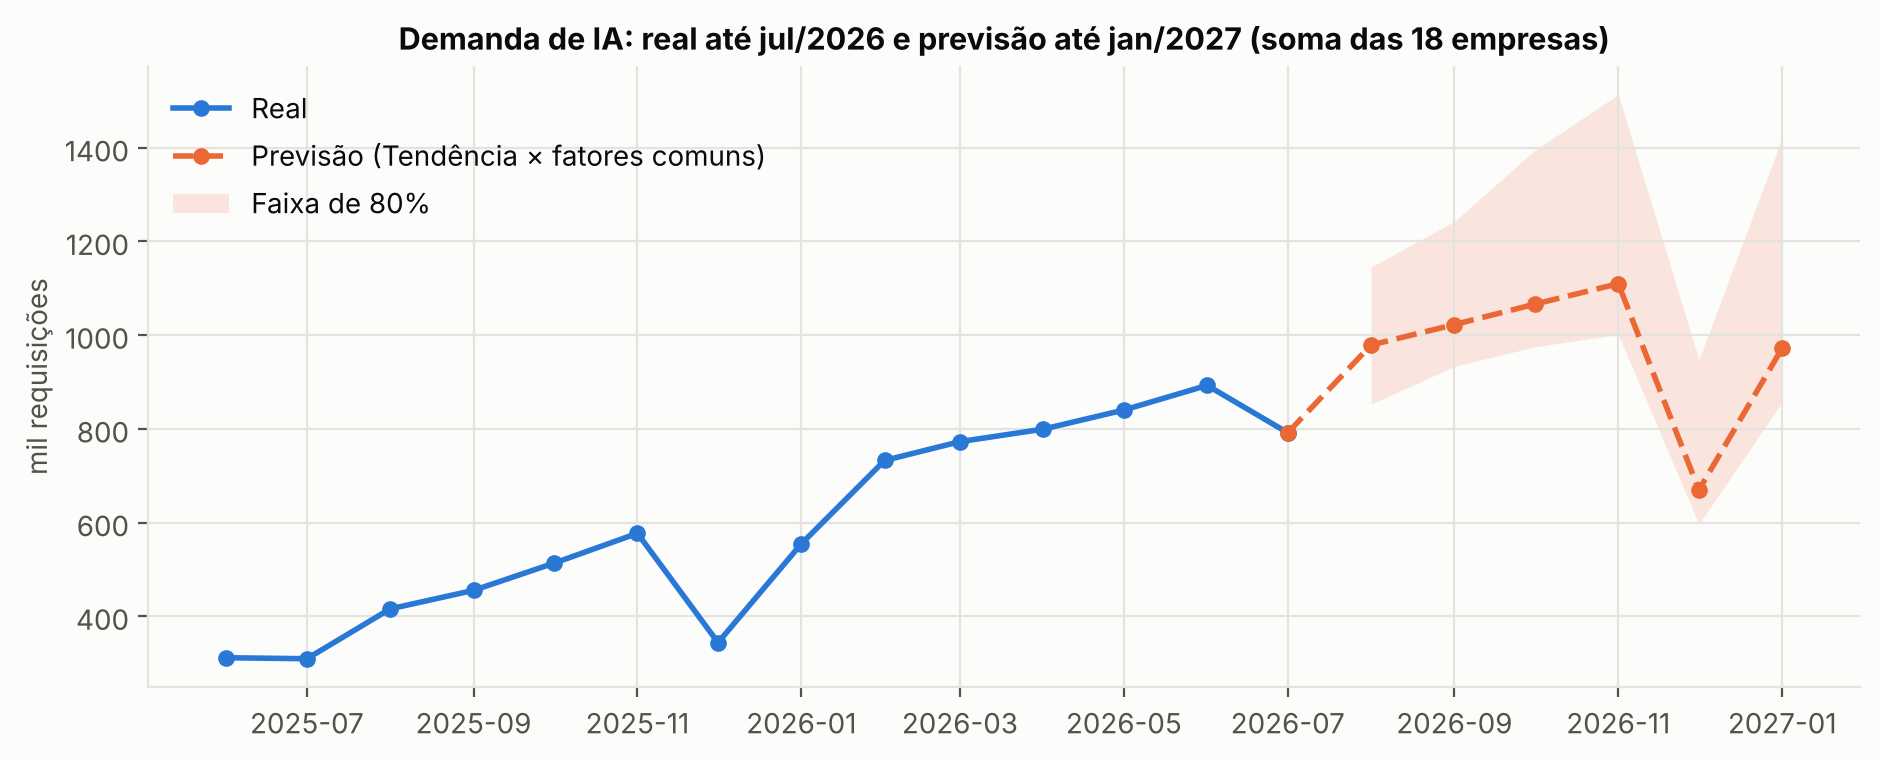

In [16]:
tot_hist = demanda.sum()
tot_prev = prev_dem.groupby('mes').previsto.sum()
# faixa do total: soma das faixas das empresas (conservadora, supõe erros perfeitamente correlacionados)
tot_lo, tot_hi = prev_dem.groupby('mes').p10.sum(), prev_dem.groupby('mes').p90.sum()
fig, ax = plt.subplots(figsize=(9.5, 3.9))
xh = [p.to_timestamp() for p in MESES]; xf = [pd.Period(m, 'M').to_timestamp() for m in tot_prev.index]
ax.plot(xh, tot_hist / 1e3, color=AZUL, marker='o', ms=5, label='Real')
ax.plot([xh[-1]] + xf, np.r_[tot_hist.iloc[-1], tot_prev.values] / 1e3, color=LARANJA, marker='o', ms=5, ls='--', label=f'Previsão ({ESCOLHIDO})')
ax.fill_between(xf, tot_lo / 1e3, tot_hi / 1e3, color=LARANJA, alpha=0.15, lw=0, label='Faixa de 80%')
ax.set(title='Demanda de IA: real até jul/2026 e previsão até jan/2027 (soma das 18 empresas)', ylabel='mil requisições')
ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG / 'fig3_previsao_total.png', dpi=150); plt.show()

- A demanda total deve passar de **792 mil requisições em julho**, mês de férias, para **979 mil em agosto**, e chegar a **1,11 milhão em novembro**.
- Em **dezembro**, cai para **670 mil**, e volta a **972 mil em janeiro**.
- Os fatores de calendário estimados são 0,58 para dezembro, 0,81 para janeiro e 0,86 para julho. Foram aprendidos com um único ciclo por empresa. Por isso, as faixas de dezembro (597 a 947 mil) e de janeiro (857 mil a 1,42 milhão) são as mais largas.

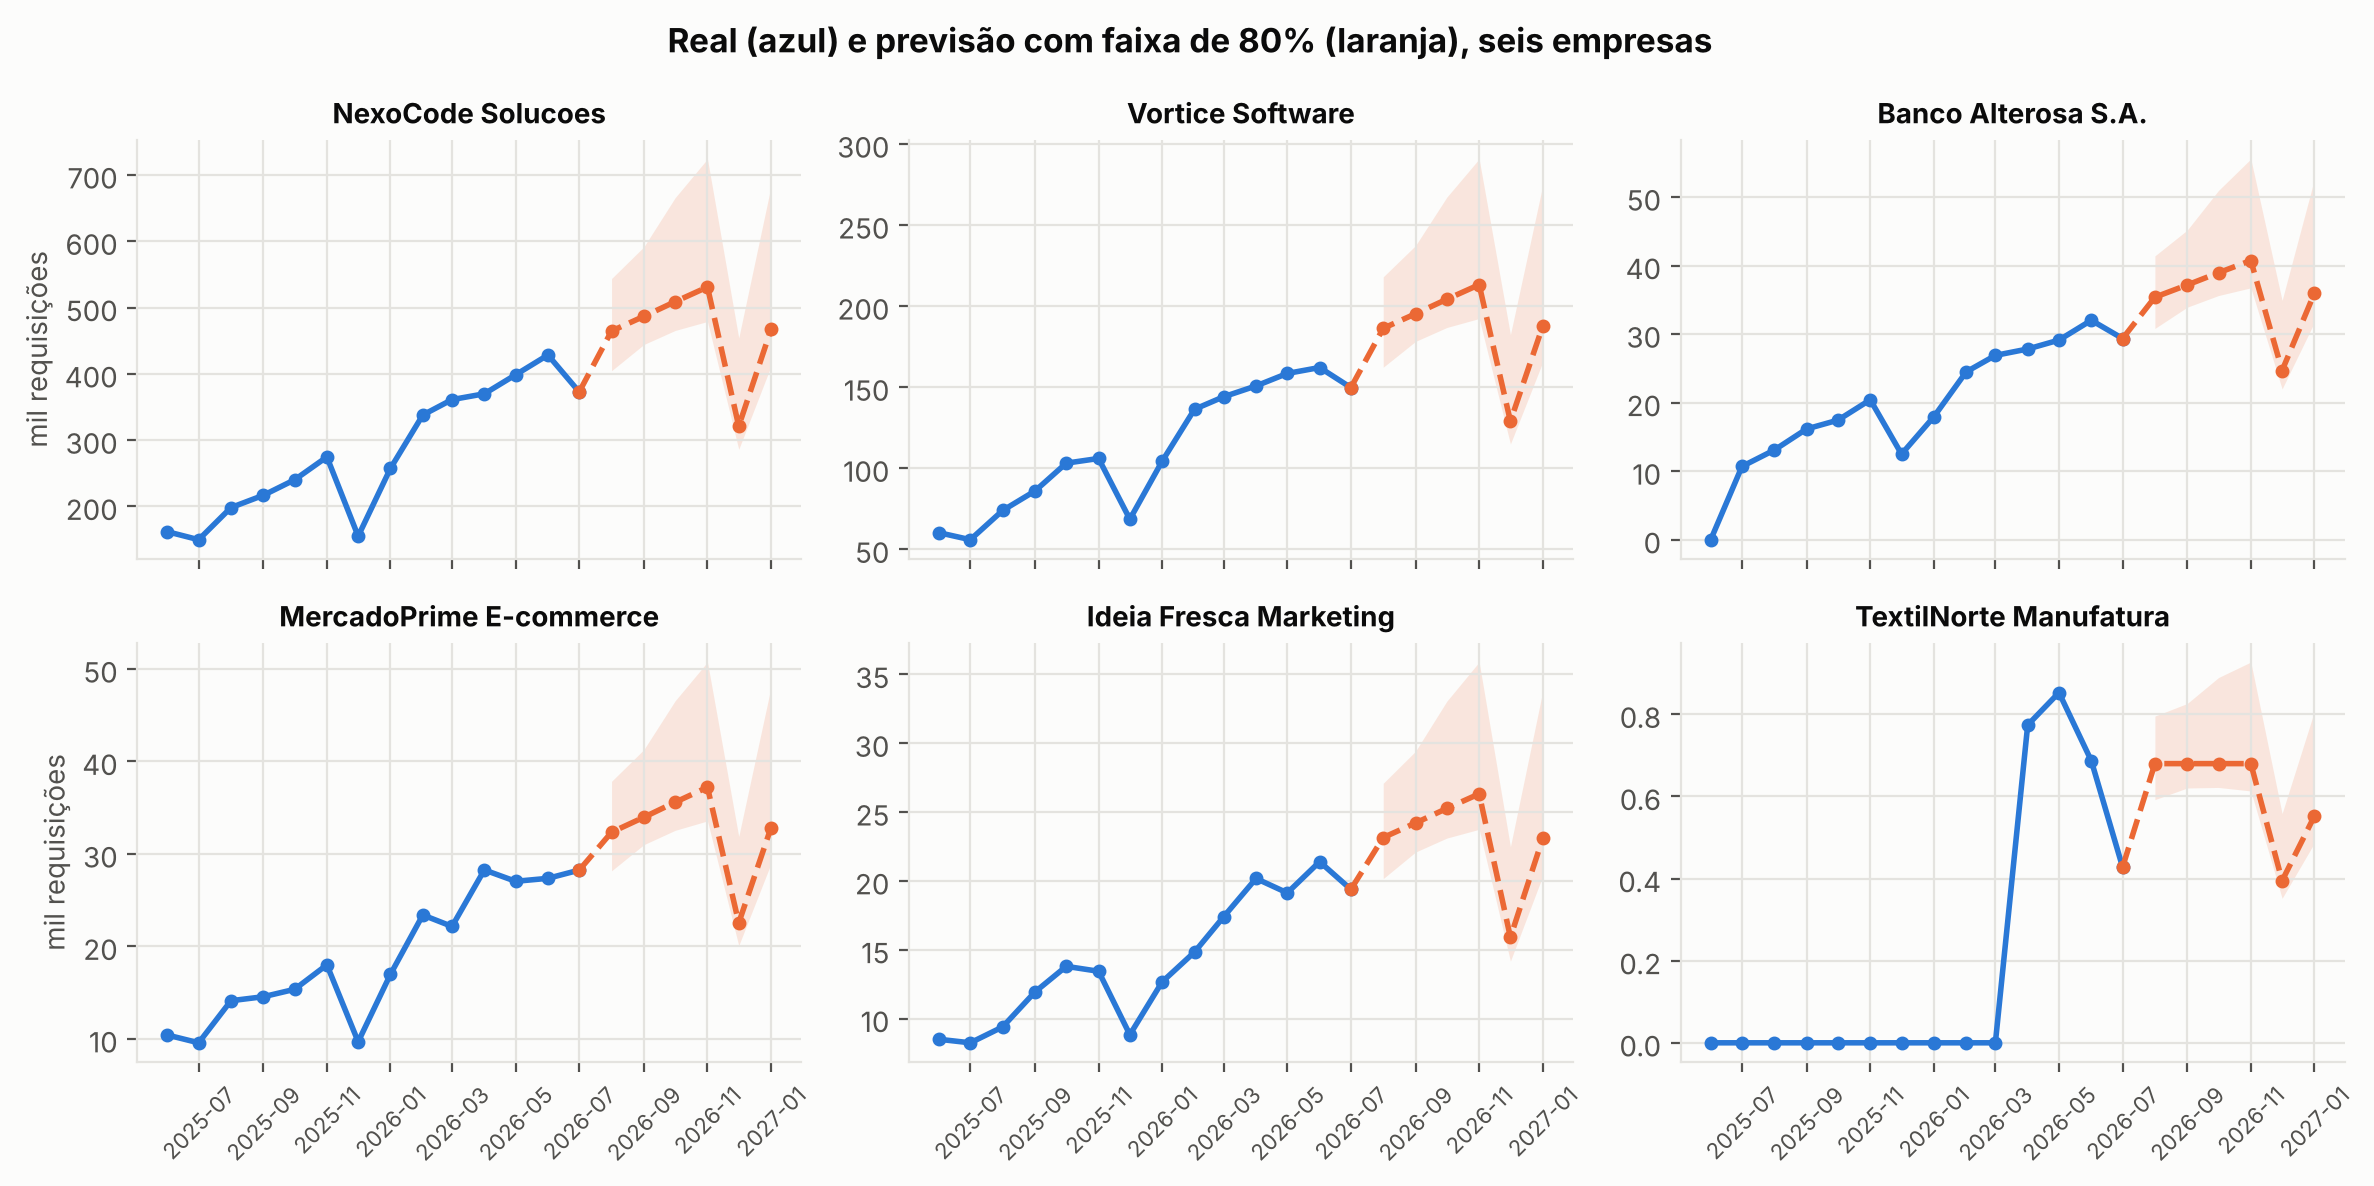

In [17]:
destaque = ['C01', 'C02', 'C06', 'C14', 'C17', 'C11']
fig, eixos = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, c in zip(eixos.flat, destaque):
    s = demanda.loc[c]; p = prev_dem[prev_dem.empresa == c]
    ax.plot(xh, s / 1e3, color=AZUL, marker='o', ms=4)
    ax.plot([xh[-1]] + xf, np.r_[s.iloc[-1], p.previsto.values] / 1e3, color=LARANJA, ls='--', marker='o', ms=4)
    ax.fill_between(xf, p.p10 / 1e3, p.p90 / 1e3, color=LARANJA, alpha=0.15, lw=0)
    ax.set_title(comp.set_index('company_id').company_name[c], fontsize=10)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
for ax in eixos[:, 0]:
    ax.set_ylabel('mil requisições')
fig.suptitle('Real (azul) e previsão com faixa de 80% (laranja), seis empresas', fontweight='bold')
fig.tight_layout(); fig.savefig(FIG / 'fig4_previsao_empresas.png', dpi=150); plt.show()

### 6.1 De 373 mil para 531 mil: o que está na extrapolação da NexoCode

A previsão da NexoCode passa de 373 mil requisições em julho para 531 mil em novembro. A conta abaixo separa o que é calendário do que é crescimento e compara com o que daria a hipótese de crescimento proporcional, para as quatro empresas de maior volume.

In [18]:
linhas = []
for c in por_empresa.index[:4]:                             # as quatro empresas de maior volume
    s = series_dem[c]; t = np.arange(len(s))
    _, b, _ = ajuste_final(s, F_lin, log=False)
    _, b_log, _ = ajuste_final(s, F_log, log=True)
    tend_jul = np.polyval(b, t[-1])
    f_lin = prever(s, len(FUTURO), 'Tendência × fatores comuns', F_lin)
    f_log = prever(s, len(FUTURO), 'Tendência log × fatores comuns', F_log)
    linhas.append({'empresa': comp.set_index('company_id').company_name[c], 'real jul/2026': s.iloc[-1],
                   'tendência jul/2026 (sem férias)': tend_jul, 'acréscimo por mês (linear)': b[0],
                   'crescimento % ago (linear)': b[0] / tend_jul, 'crescimento % jan/27 (linear)': b[0] / np.polyval(b, t[-1] + 5),
                   'crescimento % por mês (log)': np.exp(b_log[0]) - 1,
                   'nov/2026 linear': f_lin[3], 'nov/2026 log': f_log[3], 'jan/2027 linear': f_lin[5], 'jan/2027 log': f_log[5]})
aditivo = pd.DataFrame(linhas).set_index('empresa')
r = aditivo.iloc[0]
print(f"NexoCode, de jul a nov/2026: {br(r['real jul/2026'])} → {br(r['nov/2026 linear'])} requisições (+{br(r['nov/2026 linear'] - r['real jul/2026'])})")
print(f"  julho é mês de férias: sem o fator de calendário, a tendência de julho já é {br(r['tendência jul/2026 (sem férias)'])} "
      f"(+{br(r['tendência jul/2026 (sem férias)'] - r['real jul/2026'])})")
print(f"  crescimento de jul a nov: 4 × {br(r['acréscimo por mês (linear)'])} = {br(4 * r['acréscimo por mês (linear)'])} requisições "
      f"({r['crescimento % ago (linear)']:.1%} ao mês em agosto, caindo para {r['crescimento % jan/27 (linear)']:.1%} em janeiro)")
print(f"  se o crescimento fosse proporcional (log, {r['crescimento % por mês (log)']:.1%} ao mês): {br(r['nov/2026 log'])} em nov/2026")
pd.set_option('display.float_format', lambda v: br(v, 3) if abs(v) < 1 else br(v))
display(aditivo)
pd.reset_option('display.float_format')
tot_log = prever_futuro(demanda, 'Tendência log × fatores comuns', q_final)[0].groupby('mes').previsto.sum()
print('Demanda total prevista em mil requisições — linear:', (prev_dem.groupby('mes').previsto.sum() / 1e3).round(0).to_dict())
print('                                          — em log:', (tot_log / 1e3).round(0).to_dict())

NexoCode, de jul a nov/2026: 372.716 → 530.920 requisições (+158.204)
  julho é mês de férias: sem o fator de calendário, a tendência de julho já é 442.470 (+69.754)
  crescimento de jul a nov: 4 × 22.112 = 88.450 requisições (5.0% ao mês em agosto, caindo para 4.0% em janeiro)
  se o crescimento fosse proporcional (log, 8.2% ao mês): 648.466 em nov/2026


,real jul/2026,tendência jul/2026 (sem férias),acréscimo por mês (linear),crescimento % ago (linear),crescimento % jan/27 (linear),crescimento % por mês (log),nov/2026 linear,nov/2026 log,jan/2027 linear,jan/2027 log
empresa,,,,,,,,,,
NexoCode Solucoes,372716,442.470,22.112,"0,050","0,040","0,082",530.920,648.466,467.114,643.103
Vortice Software,149743,177.374,8.960,"0,051","0,040","0,085",213.213,267.164,187.718,266.830
Cronos Tech Labs,64093,75.798,1.066,"0,014","0,013","0,016",80.060,81.254,66.753,71.133
Banco Alterosa S.A.,29355,33.602,1.782,"0,053","0,042","0,086",40.731,49.935,35.975,49.931


Demanda total prevista em mil requisições — linear: {'2026-08': 979.0, '2026-09': 1023.0, '2026-10': 1066.0, '2026-11': 1110.0, '2026-12': 670.0, '2027-01': 972.0}
                                          — em log: {'2026-08': 1074.0, '2026-09': 1157.0, '2026-10': 1247.0, '2026-11': 1344.0, '2026-12': 877.0, '2027-01': 1326.0}


- **Quase metade do salto é calendário.** Julho é mês de férias (fator 0,86). Sem esse efeito, a tendência da NexoCode em julho já é de 442 mil: são 70 mil dos 158 mil de diferença.
- **O resto é crescimento aditivo:** 22 mil requisições a mais por mês, durante 4 meses, somam 88 mil. Em termos percentuais, é 5,0% ao mês em agosto e 4,0% em janeiro: a taxa cai à medida que a base cresce.
- **Com crescimento proporcional**, a taxa ficaria em 8,2% ao mês, e novembro chegaria a 648 mil. Somando as 18 empresas, novembro iria de 1,11 milhão para 1,34 milhão. Os resíduos e a confirmação (seção 5.4) mostram que a série não cresce assim.
- **Vortice e Banco Alterosa seguem o mesmo padrão:** crescimento linear de cerca de 5% ao mês em agosto, contra 8,5% e 8,6% no log. A Cronos quase não cresce (1,4% ao mês), e as duas versões dão quase o mesmo.
- **Seis meses é extrapolação.** A reta foi validada até 3 meses. Se a adoção começar a saturar, como já se vê na Vortice, a reta superestima. A faixa de 4 a 6 meses é mais larga, mas não corrige um viés.

## 7. Custo de consumo (APIs e plataformas)

O custo de consumo é tokens × preço por token. O preço depende do **mix de modelos** de cada empresa. Por exemplo, o claude-opus-4 custa 100 vezes o gpt-4o-mini por token de entrada. O preço médio por token da empresa é medido nos últimos três meses (mai a jul/2026). O mesmo backtest escolhe o modelo de previsão dos tokens.

Antes, uma conferência: o custo calculado pelos logs bate com as faturas?

In [19]:
precos = models.set_index('model_id')[['input_price_usd_per_1k_tokens', 'output_price_usd_per_1k_tokens']]
uc = uc.join(precos, on='model_id')
uc['custo_usd'] = uc.input_tokens / 1000 * uc.input_price_usd_per_1k_tokens + uc.output_tokens / 1000 * uc.output_price_usd_per_1k_tokens
uc['centro'] = uc.cost_center.fillna('SEM_CC')
chave = ['company_id', 'ai_tool_id', 'model_id', 'centro', 'mes']          # a mesma granularidade da fatura
calc = uc.groupby(chave).custo_usd.sum()
fu = fat[fat.currency == 'USD'].assign(mes=lambda d: pd.PeriodIndex(d.billing_month, freq='M'), centro=lambda d: d.cost_center.fillna('SEM_CC'))
faturado = fu.groupby(chave).total_cost.sum()
conf = pd.concat({'calculado': calc, 'faturado': faturado}, axis=1)
com_fatura = conf.dropna()
grandes = com_fatura[com_fatura.calculado >= 1]          # abaixo de US$ 1, o arredondamento para centavos distorce a razão
razao = grandes.faturado / grandes.calculado
print(f'Lançamentos esperados (empresa × ferramenta × modelo × centro de custo × mês): {len(conf)} | sem fatura: {conf.faturado.isna().sum()} ({conf.faturado.isna().mean():.1%})')
print(f'Onde há fatura, faturado / calculado = {com_fatura.faturado.sum() / com_fatura.calculado.sum():.3f} no total; '
      f'nos {len(grandes)} lançamentos de pelo menos US$ 1: mín. {razao.min():.3f}, máx. {razao.max():.3f}')
print(f'Custo de consumo calculado sem fatura correspondente: US$ {conf.loc[conf.faturado.isna(), "calculado"].sum():,.0f} '
      f'de US$ {conf.calculado.sum():,.0f}'.replace(',', '.'))

Lançamentos esperados (empresa × ferramenta × modelo × centro de custo × mês): 1850 | sem fatura: 83 (4.5%)
Onde há fatura, faturado / calculado = 1.007 no total; nos 966 lançamentos de pelo menos US$ 1: mín. 0.958, máx. 1.052
Custo de consumo calculado sem fatura correspondente: US$ 379 de US$ 12.542


Onde a fatura existe, ela fica entre −4% e +5% do calculado, o ruído normal de fatura. Onde não existe, a falta é de integração, não de consumo. **Os logs são a fonte mais completa** para prever o custo de consumo.

**Previsão dos tokens.** O mesmo backtest, com a mesma divisão entre seleção e confirmação, escolhe o modelo dos tokens. A faixa de 80% dos tokens sai dos erros do **próprio modelo de tokens**. Na versão anterior, a previsão de custo usava a faixa calibrada na demanda, bem mais estreita que o erro dos tokens.

In [20]:
METODOS_TOK = ['Ingênuo', 'Holt amortecido', 'Tendência + férias', 'Tendência × fatores comuns', 'Tendência log × fatores comuns']
bt_tok = backtest(tokens, metodos=METODOS_TOK)
bt_tok.to_csv(SAIDA / 'backtest_tokens_consumo.csv', index=False)
_, sel_tok = resumo_erros(bt_tok[bt_tok.parte == 'seleção'])
_, conf_tok = resumo_erros(bt_tok[bt_tok.parte == 'confirmação'])
sel_tok = sel_tok.sort_values('WAPE')
METODO_TOK = sel_tok.index[0]
esc_tok = bt_tok[bt_tok.metodo == METODO_TOK].assign(erro_log=erro_log)
q_tok_sel = esc_tok[esc_tok.parte == 'seleção'].groupby('h').erro_log.quantile([0.1, 0.9]).unstack()
aval_tok = esc_tok[esc_tok.parte == 'confirmação'].join(q_tok_sel, on='h')
cob_tok = aval_tok.erro_log.between(aval_tok[0.1], aval_tok[0.9]).mean()
q_tok = esc_tok.groupby('h').erro_log.quantile([0.1, 0.9]).unstack()   # faixa dos tokens: erros do próprio modelo de tokens
print(f'Modelo dos tokens escolhido na seleção: {METODO_TOK} | na confirmação: WAPE {conf_tok.loc[METODO_TOK, "WAPE"]:.1%} '
      f'(ingênuo {conf_tok.loc["Ingênuo", "WAPE"]:.1%}), cobertura da faixa de 80% {cob_tok:.0%} ({len(aval_tok)} previsões)')
pd.concat({'seleção': sel_tok, 'confirmação': conf_tok.loc[sel_tok.index]}, axis=1).round(3)

Modelo dos tokens escolhido na seleção: Tendência + férias | na confirmação: WAPE 10.8% (ingênuo 18.5%), cobertura da faixa de 80% 81% (48 previsões)


seleção                                  confirmação                                 
                                  WAPE          MAE  sMAPE   viés     n        WAPE          MAE  sMAPE   viés     n
metodo                                                                                                              
Tendência + férias               0.193  3111021.248  0.293 -0.102  72.0       0.108  1891928.332  0.233 -0.018  48.0
Tendência × fatores comuns       0.222  3572034.144  0.272  0.122  72.0       0.109  1898698.903  0.220  0.049  48.0
Tendência log × fatores comuns   0.267  4301117.210  0.307  0.169  72.0       0.153  2677871.112  0.228  0.110  48.0
Holt amortecido                  0.315  5078180.183  0.536 -0.288  72.0       0.190  3323252.073  0.246  0.084  48.0
Ingênuo                          0.335  5392688.000  0.540 -0.255  72.0       0.185  3237963.458  0.294 -0.000  48.0

In [21]:
prev_tok, _ = prever_futuro(tokens, METODO_TOK, q_tok)
recente = uc[uc.mes >= pd.Period('2026-05', 'M')]
usd_por_token = (recente.groupby('company_id').custo_usd.sum() / recente.groupby('company_id').tokens.sum()).rename('usd_por_token')
prev_tok = prev_tok.join(usd_por_token, on='empresa')
for col in ('previsto', 'p10', 'p90'):
    prev_tok[f'custo_brl_{col}'] = prev_tok[col] * prev_tok.usd_por_token * CAMBIO
prev_tok.to_csv(SAIDA / 'previsao_custo_consumo.csv', index=False)
custo_hist_brl = uc.groupby(['company_id', 'mes']).custo_usd.sum().unstack().reindex(columns=MESES).fillna(0) * CAMBIO
resumo_consumo = pd.DataFrame({
    'consumo_jul2026_brl': custo_hist_brl[MESES[-1]],
    'previsto_medio_ago_jan_brl': prev_tok.groupby('empresa').custo_brl_previsto.mean(),
    'faixa_80_p10': prev_tok.groupby('empresa').custo_brl_p10.mean(),
    'faixa_80_p90': prev_tok.groupby('empresa').custo_brl_p90.mean(),
    'previsto_jan2027_brl': prev_tok[prev_tok.mes == '2027-01'].set_index('empresa').custo_brl_previsto,
}).dropna().join(comp.set_index('company_id').company_name)
print('Modelo dos tokens:', METODO_TOK, '| faixa de 80% dos tokens (quantis do log do erro):', q_tok.round(2).to_dict('index'))
resumo_consumo.round(0)

Modelo dos tokens: Tendência + férias | faixa de 80% dos tokens (quantis do log do erro): {1: {0.1: -0.42, 0.9: 0.56}, 2: {0.1: -0.37, 0.9: 0.38}, 3: {0.1: -0.4, 0.9: 0.39}}


,consumo_jul2026_brl,previsto_medio_ago_jan_brl,faixa_80_p10,faixa_80_p90,previsto_jan2027_brl,company_name
C01,1311.0,1657.0,1050.0,2660.0,1668.0,NexoCode Solucoes
C02,2239.0,2610.0,1652.0,4193.0,2701.0,Vortice Software
C03,69.0,154.0,98.0,247.0,140.0,Piloto Digital Sistemas
C04,311.0,342.0,218.0,548.0,302.0,Cronos Tech Labs
C14,1410.0,1552.0,982.0,2493.0,1609.0,MercadoPrime E-commerce
C15,396.0,624.0,397.0,1000.0,580.0,Prisma Consultoria Empresarial
C17,1444.0,1261.0,795.0,2031.0,1424.0,Ideia Fresca Marketing
C18,177.0,301.0,192.0,481.0,262.0,Estrela Marketing Digital


- **O consumo é pequeno perto dos assentos.** Somando as 8 empresas, são cerca de **R$ 8 a 9 mil por mês**, menos de 2% do custo total de IA.
- **Modelo:** a seleção escolhe **tendência + férias**, com 19,3% de WAPE, contra 22,2% dos fatores comuns e 33,5% do ingênuo. Na confirmação, ele erra **10,8%**, contra 18,5% do ingênuo, e a faixa de 80% cobre **81%** das 48 previsões.
- **Por que o erro é maior que o da demanda:** poucos colaboradores de TI e Dados concentram o consumo, e qualquer variação deles pesa. A faixa dos tokens vai de −34% a +75% a 1 mês, contra −13% a +17% da demanda.

## 8. Orçamento: retrato atual com o componente previsto de consumo

O orçamento da base é definido por **centro de custo**, ou seja, por departamento. Por isso a comparação é feita nesse nível. Somar por empresa esconderia o que a Pesquisa Operacional já mostrou: dentro da mesma empresa, um departamento pode estourar enquanto outro mal usa o que tem.

O custo mensal de IA de um centro de custo tem duas partes, de natureza diferente:

| Parte | De onde vem | É previsão? |
|---|---|---|
| **Assentos** (licenças por usuário, em R$) | Faturados em jul/2026 e mantidos constantes | **Não.** É o retrato atual. O assento é contratual: depende de quantas licenças a empresa mantém, e a base registra só o status atual de cada licença. Nenhum modelo desta análise prevê esse valor |
| **Consumo** (APIs, em US$ convertidos a R$ 5,50) | Previsão da seção 7, por empresa, distribuída entre os centros de custo conforme a participação de cada um em mai a jul/2026 | **Sim**, com faixa de 80% |

Por isso a tabela traz duas situações:
- **Situação atual:** assentos e consumo observados em jul/2026, contra o orçamento. É um **diagnóstico**; não sai de modelo.
- **Situação projetada:** assentos de jul/2026 mais o consumo previsto (média de ago/2026 a jan/2027). Mostra o que a previsão acrescenta ao retrato. "Risco" quer dizer que o centro passa do orçamento no limite superior da faixa de 80% do consumo.

O orçamento de referência é a **média mensal orçada em 2026** para o centro de custo. A base não traz orçamento depois de julho de 2026. Os assentos e o consumo de colaboradores sem centro de custo (1,9% do cadastro) não entram na comparação.

In [22]:
orc['mes'] = pd.PeriodIndex(orc.year.astype(str) + '-' + orc.month.astype(str).str.zfill(2), freq='M')
orc_cc = orc[orc.mes.dt.year == 2026].groupby(['company_id', 'cost_center']).budget_amount.mean().rename('orcamento_mensal_2026')
# 1. retrato de jul/2026: assentos faturados (BRL) e consumo observado (USD → BRL)
assentos_cc = fat[(fat.billing_month == '2026-07') & (fat.currency == 'BRL')].groupby(['company_id', 'cost_center']).total_cost.sum().rename('assentos_jul2026')
cons_jul = uc[uc.mes == MESES[-1]].groupby(['company_id', 'centro']).custo_usd.sum() * CAMBIO
cons_jul = cons_jul.rename('consumo_jul2026').rename_axis(['company_id', 'cost_center'])
# 2. componente previsto: consumo médio de ago/2026 a jan/2027, distribuído pela participação do centro em mai a jul/2026
part = (recente.groupby(['company_id', 'centro']).custo_usd.sum() / recente.groupby('company_id').custo_usd.sum()).rename('participacao').reset_index()
part = part.join(prev_tok.groupby('empresa')[['custo_brl_previsto', 'custo_brl_p10', 'custo_brl_p90']].mean(), on='company_id')
for col, base in (('consumo_previsto', 'custo_brl_previsto'), ('consumo_previsto_p10', 'custo_brl_p10'), ('consumo_previsto_p90', 'custo_brl_p90')):
    part[col] = part.participacao * part[base]
consumo_cc = part.rename(columns={'centro': 'cost_center'}).set_index(['company_id', 'cost_center'])[['consumo_previsto', 'consumo_previsto_p10', 'consumo_previsto_p90']]
cc = pd.concat([orc_cc, assentos_cc, cons_jul, consumo_cc], axis=1)
cc = cc[cc.index.get_level_values('cost_center') != 'SEM_CC'].fillna(0)
cc = cc[cc.orcamento_mensal_2026 > 0]

def situacao(uso, uso_p90=None):
    acima_p90 = uso_p90 > 1 if uso_p90 is not None else np.zeros(len(uso), bool)
    return np.select([uso > 1, acima_p90, uso > 0.9], ['Acima do orçamento', 'Risco: acima no limite superior da faixa de 80%', 'Atenção: entre 90% e 100%'], 'Dentro do orçamento')

cc['uso_atual'] = (cc.assentos_jul2026 + cc.consumo_jul2026) / cc.orcamento_mensal_2026
cc['situacao_atual'] = situacao(cc.uso_atual)
cc['custo_mensal_projetado'] = cc.assentos_jul2026 + cc.consumo_previsto
cc['parcela_prevista'] = cc.consumo_previsto / cc.custo_mensal_projetado
for suf, col in (('', 'consumo_previsto'), ('_p10', 'consumo_previsto_p10'), ('_p90', 'consumo_previsto_p90')):
    cc[f'uso_projetado{suf}'] = (cc.assentos_jul2026 + cc[col]) / cc.orcamento_mensal_2026
cc['situacao_projetada'] = situacao(cc.uso_projetado, cc.uso_projetado_p90)
cc = cc.reset_index()
nomes_dep = ler('departments').set_index('department_id').department_name
cc['departamento'] = cc.cost_center.str.replace('CC-', '', regex=False).map(nomes_dep)
cc = cc.merge(comp[['company_id', 'company_name']], on='company_id').sort_values('uso_projetado', ascending=False).reset_index(drop=True)
cc.to_csv(SAIDA / 'orcamento_previsto_por_centro_de_custo.csv', index=False)

total = cc[['assentos_jul2026', 'consumo_jul2026', 'consumo_previsto']].sum()
custo_total = total.assentos_jul2026 + total.consumo_previsto
print(f"Custo mensal projetado dos {len(cc)} centros de custo: R$ {br(custo_total)}, dos quais {total.assentos_jul2026 / custo_total:.1%} "
      f"são assentos de jul/2026 mantidos constantes (retrato) e {total.consumo_previsto / custo_total:.1%} é consumo previsto")
print(f"Consumo: R$ {br(total.consumo_jul2026)} observados em jul/2026 → R$ {br(total.consumo_previsto)} previstos por mês "
      f"(faixa de 80%: R$ {br(cc.consumo_previsto_p10.sum())} a R$ {br(cc.consumo_previsto_p90.sum())})")
excesso = lambda custo: (custo - cc.orcamento_mensal_2026).clip(lower=0).sum()
print(f"Acima do orçamento — retrato de jul/2026: {(cc.situacao_atual == 'Acima do orçamento').sum()} centros, excesso de R$ "
      f"{br(excesso(cc.assentos_jul2026 + cc.consumo_jul2026))}/mês | com o consumo previsto: {(cc.situacao_projetada == 'Acima do orçamento').sum()} centros, "
      f"R$ {br(excesso(cc.custo_mensal_projetado))}/mês")
mudam = cc[cc.situacao_atual != cc.situacao_projetada]
print(f"Centros que mudam de situação por causa da previsão de consumo: {len(mudam)}", 
      [f"{r.company_name} · {r.departamento}: {r.situacao_atual} → {r.situacao_projetada}" for r in mudam.itertuples()])
display(pd.crosstab(cc.situacao_atual, cc.situacao_projetada, margins=True, margins_name='total'))
cc.head(15)[['company_name', 'departamento', 'orcamento_mensal_2026', 'assentos_jul2026', 'consumo_jul2026', 'consumo_previsto',
             'consumo_previsto_p10', 'consumo_previsto_p90', 'uso_atual', 'uso_projetado', 'situacao_projetada']].round(2)

Custo mensal projetado dos 161 centros de custo: R$ 497.244, dos quais 98.3% são assentos de jul/2026 mantidos constantes (retrato) e 1.7% é consumo previsto
Consumo: R$ 7.289 observados em jul/2026 → R$ 8.298 previstos por mês (faixa de 80%: R$ 5.254 a R$ 13.326)
Acima do orçamento — retrato de jul/2026: 35 centros, excesso de R$ 83.366/mês | com o consumo previsto: 35 centros, R$ 83.794/mês
Centros que mudam de situação por causa da previsão de consumo: 1 ['MercadoPrime E-commerce · Tecnologia da Informacao: Dentro do orçamento → Risco: acima no limite superior da faixa de 80%']


situacao_projetada,Acima do orçamento,Atenção: entre 90% e 100%,Dentro do orçamento,Risco: acima no limite superior da faixa de 80%,total
situacao_atual,,,,,
Acima do orçamento,35,0,0,0,35
Atenção: entre 90% e 100%,0,3,0,0,3
Dentro do orçamento,0,0,122,1,123
total,35,3,122,1,161


,company_name,departamento,orcamento_mensal_2026,assentos_jul2026,consumo_jul2026,consumo_previsto,consumo_previsto_p10,consumo_previsto_p90,uso_atual,uso_projetado,situacao_projetada
0,NexoCode Solucoes,Engenharia de Software,6747.18,23281.09,162.39,194.32,123.11,311.92,3.47,3.48,Acima do orçamento
1,Quimica Bandeirantes,Producao,2538.44,7029.87,0.00,0.00,0.00,0.00,2.77,2.77,Acima do orçamento
2,Fincredi Solucoes Financeiras,Atendimento ao Cliente,887.98,2299.40,0.00,0.00,0.00,0.00,2.59,2.59,Acima do orçamento
3,ByteFlow Engenharia de Software,Qualidade (QA),527.11,1338.33,0.00,0.00,0.00,0.00,2.54,2.54,Acima do orçamento
4,Estrela Marketing Digital,Atendimento a Clientes (Account),2030.64,4895.05,1.55,4.86,3.10,7.78,2.41,2.41,Acima do orçamento
5,Vortice Software,Produto,1595.45,3508.53,223.14,129.78,82.12,208.48,2.34,2.28,Acima do orçamento
6,Compra Certa Varejo,Comercial e Compras,2897.89,6446.23,0.00,0.00,0.00,0.00,2.22,2.22,Acima do orçamento
7,Banco Alterosa S.A.,Comercial,6624.82,13793.44,0.00,0.00,0.00,0.00,2.08,2.08,Acima do orçamento
8,MercadoPrime E-commerce,Logistica e Supply Chain,1729.48,3508.63,11.29,49.99,31.63,80.30,2.04,2.06,Acima do orçamento
9,NexoCode Solucoes,Vendas,6431.40,10442.27,186.92,202.91,128.56,325.71,1.65,1.66,Acima do orçamento


In [23]:
soma = ['orcamento_mensal_2026', 'assentos_jul2026', 'consumo_jul2026', 'consumo_previsto', 'consumo_previsto_p10', 'consumo_previsto_p90']
emp_orc = cc.groupby(['company_id', 'company_name'])[soma].sum()
emp_orc['uso_atual'] = (emp_orc.assentos_jul2026 + emp_orc.consumo_jul2026) / emp_orc.orcamento_mensal_2026
emp_orc['uso_projetado'] = (emp_orc.assentos_jul2026 + emp_orc.consumo_previsto) / emp_orc.orcamento_mensal_2026
emp_orc['uso_projetado_p90'] = (emp_orc.assentos_jul2026 + emp_orc.consumo_previsto_p90) / emp_orc.orcamento_mensal_2026
ids = emp_orc.index.get_level_values(0)
emp_orc['centros_acima_atual'] = cc[cc.situacao_atual == 'Acima do orçamento'].groupby('company_id').size().reindex(ids).fillna(0).astype(int).values
emp_orc['centros_acima_projetado'] = cc[cc.situacao_projetada == 'Acima do orçamento'].groupby('company_id').size().reindex(ids).fillna(0).astype(int).values
emp_orc['centros'] = cc.groupby('company_id').size().reindex(ids).values
emp_orc = emp_orc.sort_values('uso_projetado', ascending=False)
emp_orc.to_csv(SAIDA / 'orcamento_previsto_por_empresa.csv')
emp_orc[['orcamento_mensal_2026', 'assentos_jul2026', 'consumo_previsto', 'uso_atual', 'uso_projetado', 'uso_projetado_p90',
         'centros_acima_atual', 'centros_acima_projetado', 'centros']].round(2)

,,orcamento_mensal_2026,assentos_jul2026,consumo_previsto,uso_atual,uso_projetado,uso_projetado_p90,centros_acima_atual,centros_acima_projetado,centros
company_id,company_name,,,,,,,,,
C16,ServPro Facilities,12161.84,12983.76,0.00,1.07,1.07,1.07,5,5,7
C06,Banco Alterosa S.A.,92621.79,93564.09,0.00,1.01,1.01,1.01,5,5,8
C01,NexoCode Solucoes,95630.09,79487.91,1645.37,0.84,0.85,0.86,4,4,11
C18,Estrela Marketing Digital,22581.31,18125.09,298.36,0.81,0.82,0.82,2,2,7
C02,Vortice Software,42626.45,30874.34,2512.93,0.78,0.78,0.82,5,5,11
C09,Metalurgica Vale Forte,92805.43,72541.00,0.00,0.78,0.78,0.78,3,3,9
C08,Fincredi Solucoes Financeiras,13900.64,10599.80,0.00,0.76,0.76,0.76,1,1,8
C12,Compra Certa Varejo,65878.05,49814.27,0.00,0.76,0.76,0.76,3,3,9
C10,Quimica Bandeirantes,25332.24,17551.08,0.00,0.69,0.69,0.69,2,2,9


- **O retrato já mostra o problema.** Com os assentos e o consumo de jul/2026, **35 dos 161 centros de custo** estão acima do orçamento, com excesso somado de **R$ 83 mil por mês**, e outros 3 estão entre 90% e 100%.
- **A previsão quase não muda o quadro.** Os assentos são **98,3%** do custo mensal projetado; o consumo previsto, 1,7%. Com ele, os mesmos 35 centros ficam acima, o excesso vai a R$ 84 mil e só **1 centro muda de situação**: Tecnologia da Informação da MercadoPrime, que passa do orçamento no limite superior da faixa do consumo.
- **O maior estouro é Engenharia de Software da NexoCode:** 347% do orçamento no retrato e 348% com o consumo previsto. É o mesmo achado da Pesquisa Operacional, que mediu 3,5 vezes o orçamento.
- **Somando por empresa, só ServPro (107%) e Banco Alterosa (101%) passam do orçamento.** A soma esconde os estouros: a NexoCode fica em 85% no total, mas tem 4 centros de custo acima.
- **Leitura para o produto:** o alerta "orçamento de IA em risco" é, hoje, um diagnóstico da distribuição das licenças, com um componente previsto pequeno. É o que o modelo de Machine Learning (quem deve ter licença) e a Pesquisa Operacional (como redistribuir dentro do orçamento) atacam. A parte prevista pesa mais onde o consumo é maior: Ideia Fresca (29% do custo projetado), MercadoPrime (9%) e Vortice (8%).

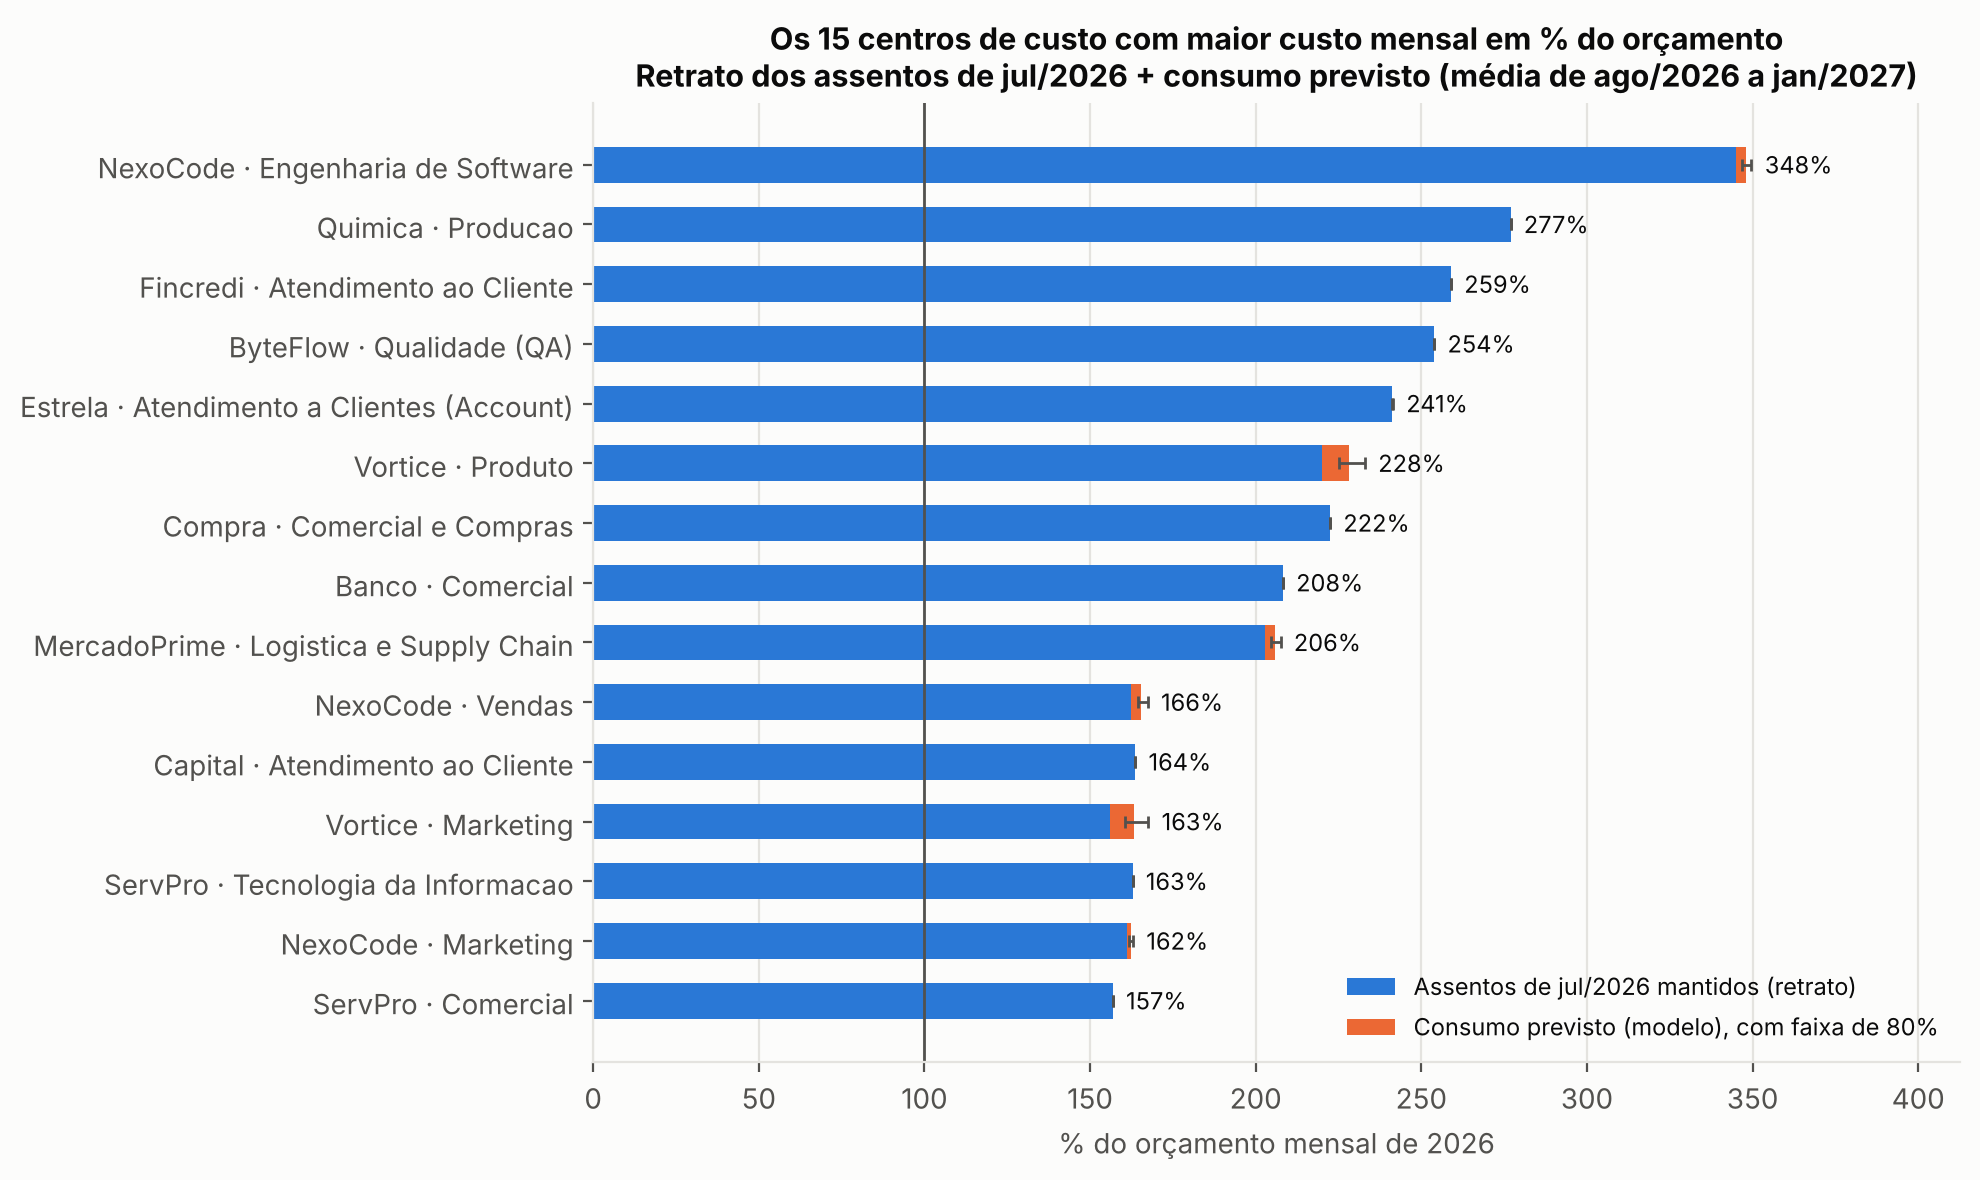

In [24]:
top = cc.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_axisbelow(True)
rotulos = [f"{n.split()[0]} · {d}" for n, d in zip(top.company_name, top.departamento)]
assentos_pct = top.assentos_jul2026 / top.orcamento_mensal_2026 * 100
consumo_pct = top.consumo_previsto / top.orcamento_mensal_2026 * 100
ax.barh(rotulos, assentos_pct, color=AZUL, height=0.6, label='Assentos de jul/2026 mantidos (retrato)')
ax.barh(rotulos, consumo_pct, left=assentos_pct, color=LARANJA, height=0.6, label='Consumo previsto (modelo), com faixa de 80%')
err = np.vstack([(top.consumo_previsto - top.consumo_previsto_p10), (top.consumo_previsto_p90 - top.consumo_previsto)]) / top.orcamento_mensal_2026.values * 100
ax.errorbar(assentos_pct + consumo_pct, np.arange(len(top)), xerr=err, fmt='none', ecolor=TINTA2, elinewidth=1, capsize=2)
ax.axvline(100, color=TINTA2, lw=1)
for i, (v, fim) in enumerate(zip(top.uso_projetado * 100, top.uso_projetado_p90 * 100)):
    ax.text(fim + 4, i, f'{v:.0f}%', va='center', fontsize=8.5, color=TINTA)
ax.set(title='Os 15 centros de custo com maior custo mensal em % do orçamento\nRetrato dos assentos de jul/2026 + consumo previsto (média de ago/2026 a jan/2027)',
       xlabel='% do orçamento mensal de 2026', xlim=(0, top.uso_projetado_p90.max() * 118))
ax.legend(loc='lower right', fontsize=8.5); ax.grid(axis='y', visible=False)
fig.tight_layout(); fig.savefig(FIG / 'fig5_orcamento_centros_de_custo.png', dpi=150); plt.show()

## 9. Conclusões

Os números abaixo saem das tabelas acima.

In [25]:
s, c_ = tab_sel.loc[ESCOLHIDO], tab_conf.loc[ESCOLHIDO]
print(f"Backtest: {len(grade)} previsões possíveis por modelo, {avaliadas} avaliadas "
      f"({(grade.motivo.str.contains('jul/2026')).sum()} com alvo depois de jul/2026, {(grade.motivo.str.contains('3 meses')).sum()} sem 3 meses de uso na origem)")
print(f"Escolha (seleção, alvos até {FIM_SELECAO}): {ESCOLHIDO}, WAPE {s['WAPE geral']:.1%} | versão em log {tab_sel.loc['Tendência log × fatores comuns', 'WAPE geral']:.1%} "
      f"| ingênuo {tab_sel.loc['Ingênuo', 'WAPE geral']:.1%}")
print(f"Confirmação (origens abr a jun/2026): WAPE {c_['WAPE geral']:.1%} ({c_['WAPE h=1']:.1%}, {c_['WAPE h=2']:.1%}, {c_['WAPE h=3']:.1%} de 1 a 3 meses), "
      f"sMAPE {c_['sMAPE geral']:.1%}, viés {c_['viés']:+.1%} | log: WAPE {tab_conf.loc['Tendência log × fatores comuns', 'WAPE geral']:.1%}, viés "
      f"{tab_conf.loc['Tendência log × fatores comuns', 'viés']:+.1%} | ingênuo: {tab_conf.loc['Ingênuo', 'WAPE geral']:.1%}")
print(f"Por empresa (confirmação): WAPE mediano {por_empresa.WAPE_confirmacao.median():.1%}; de {por_empresa.WAPE_confirmacao.min():.1%} a {por_empresa.WAPE_confirmacao.max():.1%}; "
      f"NexoCode é {por_empresa.loc['C01', 'peso_no_WAPE']:.0%} do volume")
print(f"Faixa de 80% calibrada na seleção: cobertura de {aval.dentro.mean():.0%} na confirmação ({', '.join(f'{v:.0%}' for v in cobertura.values)} de 1 a 3 meses)")
print(f"Demanda total prevista: ago/2026 {br(tot_prev.iloc[0] / 1e3)} mil, nov/2026 {br(tot_prev.loc['2026-11'] / 1e3)} mil, dez/2026 {br(tot_prev.loc['2026-12'] / 1e3)} mil, "
      f"jan/2027 {br(tot_prev.loc['2027-01'] / 1e3)} mil (jul/2026 real: {br(tot_hist.iloc[-1] / 1e3)} mil)")
print(f"Tokens de consumo: {METODO_TOK}, WAPE na confirmação {conf_tok.loc[METODO_TOK, 'WAPE']:.1%} (ingênuo {conf_tok.loc['Ingênuo', 'WAPE']:.1%}), cobertura {cob_tok:.0%}")
print(f"Orçamento: {(cc.situacao_atual == 'Acima do orçamento').sum()} de {len(cc)} centros de custo acima já no retrato de jul/2026; "
      f"{(cc.situacao_projetada == 'Acima do orçamento').sum()} com o consumo previsto; "
      f"assentos = {total.assentos_jul2026 / (total.assentos_jul2026 + total.consumo_previsto):.0%} do custo projetado")
print(f'Tempo total: {time.time() - inicio:.0f} s')
por_empresa[['empresa', 'peso_no_WAPE', 'WAPE_confirmacao', 'WAPE_ingenuo_confirmacao']].round(3)

Backtest: 378 previsões possíveis por modelo, 262 avaliadas (54 com alvo depois de jul/2026, 62 sem 3 meses de uso na origem)
Escolha (seleção, alvos até 2026-04): Tendência × fatores comuns, WAPE 7.8% | versão em log 8.3% | ingênuo 26.7%
Confirmação (origens abr a jun/2026): WAPE 4.0% (3.9%, 4.4%, 3.8% de 1 a 3 meses), sMAPE 7.3%, viés +1.8% | log: WAPE 8.3%, viés +7.4% | ingênuo: 7.9%
Por empresa (confirmação): WAPE mediano 5.8%; de 1.7% a 60.5%; NexoCode é 48% do volume
Faixa de 80% calibrada na seleção: cobertura de 79% na confirmação (92%, 70%, 56% de 1 a 3 meses)
Demanda total prevista: ago/2026 979 mil, nov/2026 1.110 mil, dez/2026 670 mil, jan/2027 972 mil (jul/2026 real: 792 mil)
Tokens de consumo: Tendência + férias, WAPE na confirmação 10.8% (ingênuo 18.5%), cobertura 81%
Orçamento: 35 de 161 centros de custo acima já no retrato de jul/2026; 35 com o consumo previsto; assentos = 98% do custo projetado
Tempo total: 7 s


,empresa,peso_no_WAPE,WAPE_confirmacao,WAPE_ingenuo_confirmacao
company_id,,,,
C01,NexoCode Solucoes,0.475,0.022,0.085
C02,Vortice Software,0.187,0.050,0.048
C04,Cronos Tech Labs,0.081,0.067,0.056
C06,Banco Alterosa S.A.,0.036,0.018,0.071
C18,Estrela Marketing Digital,0.034,0.053,0.105
C14,MercadoPrime E-commerce,0.033,0.056,0.027
C15,Prisma Consultoria Empresarial,0.031,0.072,0.112
C03,Piloto Digital Sistemas,0.030,0.092,0.174
C17,Ideia Fresca Marketing,0.024,0.028,0.063


### Resumo

| Entrega | Resultado |
|---|---|
| Modelo de demanda | Tendência linear por empresa (crescimento aditivo) × fatores de calendário comuns (dezembro 0,58, janeiro 0,81, julho 0,86) |
| Backtest | 7 origens × 18 empresas × 3 horizontes = 378 previsões possíveis por modelo; 262 avaliadas (54 com alvo depois de jul/2026 e 62 com menos de 3 meses de uso descartadas) |
| Escolha | Na seleção (alvos até abr/2026): WAPE de 7,8%, contra 8,3% da versão em log e 26,7% do ingênuo |
| Confirmação | Origens de abr a jun/2026: WAPE de 4,0%, **sMAPE de 7,3%**, viés de +1,8%; ingênuo, 7,9%. O período não tem dezembro nem janeiro; em janeiro de 2026, o erro foi de 13,9% |
| Erro por empresa | A NexoCode é 48% do volume e erra 2,2%; sem ela, o WAPE é 5,8%. WAPE mediano por empresa de 5,8%, de 1,7% a 60,5%, com cinco empresas pequenas acima de 10% (tabela abaixo) |
| Diagnóstico dos resíduos | A tendência linear passa nos testes de autocorrelação, heterocedasticidade e curvatura. A versão em log tem curvatura côncava em NexoCode, Vortice e Piloto e superestima 7,4% na confirmação. Ressalva: a Vortice desacelera |
| Intervalos | Faixa de 80% calibrada na seleção: cobertura de 79% na confirmação (92%, 70% e 56% de 1 a 3 meses) |
| Previsão | 979 mil requisições em ago/2026, 1,11 milhão em nov/2026, 670 mil em dez/2026 e 972 mil em jan/2027 |
| Custo de consumo | Menos de 2% do custo. Tokens com WAPE de 10,8% na confirmação e faixa própria, com cobertura de 81% |
| Orçamento (diagnóstico) | 35 de 161 centros de custo acima do orçamento já no retrato de jul/2026. Os assentos são 98% do custo projetado, e a previsão de consumo muda a situação de 1 centro |

**Limitações**
- Há só 14 meses de histórico e um ciclo anual. Os fatores de dezembro e janeiro vêm de uma única observação por empresa, e a validação vai até 3 meses à frente. De 4 a 6 meses, a faixa é extrapolada.
- A confirmação tem 3 origens e cai num período sem dezembro e janeiro. O erro de 4,0% é o de meses comuns.
- A base é sintética. Tendência e calendário seguem regras simples na geração, o que favorece modelos com essa mesma estrutura. Dados reais terão choques (lançamento de ferramenta, mudança de preço) que nenhum desses modelos antecipa.
- Os assentos são mantidos constantes. Renovação, expiração e realocação de contratos mudam esse valor, e a base registra só o status atual de cada licença.

**Próximo passo no produto:** transformar a previsão por centro de custo no alerta "orçamento de IA em risco" do MVP, com a faixa de 80% exibida, e registrar a execução dessa tela como evidência de integração. O orçamento projetado também pode entrar na restrição R1 da Pesquisa Operacional no lugar da média histórica.